In [1]:
import loompy
import scvelo as scv

In [2]:
import os, glob, re, pickle
from functools import partial
from collections import OrderedDict
import operator as op
from cytoolz import compose

import pandas as pd
import seaborn as sns
import numpy as np
import scanpy as sc
import scanpy.external as sce
import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
sc.settings.verbosity = 3
sc.logging.print_header()
sc.set_figure_params(dpi=100, dpi_save=600)

from pyscenic.export import export2loom, add_scenic_metadata
from pyscenic.utils import load_motifs
from pyscenic.transform import df2regulons
from pyscenic.aucell import aucell
from pyscenic.binarization import binarize
from pyscenic.rss import regulon_specificity_scores
from pyscenic.plotting import plot_binarization, plot_rss

from IPython.display import HTML, display

import base64
import glob
import json
import loompy as lp
import os
import scipy
import zlib

from matplotlib import rcParams
from adjustText import adjust_text

scanpy==1.8.2 anndata==0.8.0 umap==0.5.2 numpy==1.21.6 scipy==1.7.3 pandas==1.3.5 scikit-learn==1.0.2 statsmodels==0.13.1 python-igraph==0.9.10 louvain==0.7.1 pynndescent==0.5.5


In [3]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_versions()
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(3, 3), facecolor='white')

The `sinfo` package has changed name and is now called `session_info` to become more discoverable and self-explanatory. The `sinfo` PyPI package will be kept around to avoid breaking old installs and you can downgrade to 0.3.2 if you want to use it without seeing this message. For the latest features and bug fixes, please install `session_info` instead. The usage and defaults also changed slightly, so please review the latest README at https://gitlab.com/joelostblom/session_info.
-----
anndata     0.8.0
scanpy      1.8.2
sinfo       0.3.4
-----
PIL                         9.1.0
adjustText                  NA
asttokens                   NA
attr                        21.4.0
backcall                    0.2.0
beta_ufunc                  NA
binom_ufunc                 NA
boltons                     NA
cffi                        1.15.0
cloudpickle                 2.0.0
colorama                    0.4.4
ctxcore                     0.1.1
cycler                      0.10.0
cython_runtime     

In [4]:
# set a working directory
wdir = "/Users/KKo1/Documents/Ko/pyscenic/4NQO"
os.chdir(wdir)
# path to loom file with basic filtering applied (this will be created in the "initial filtering" step below).
f_loom_path_scenic = "/Users/KKo1/Documents/Ko/pyscenic/4NQO/CIS_filtered.loom"

In [5]:
# create these folders manually
AUXILLIARIES_FOLDERNAME = "/Users/KKo1/Documents/Ko/pyscenic/4NQO/auxilliaries/"
RESULTS_FOLDERNAME = "/Users/KKo1/Documents/Ko/pyscenic/4NQO/CIS_dynamo_1st/results/"
FIGURES_FOLDERNAME = "/Users/KKo1/Documents/Ko/pyscenic/4NQO/CIS_dynamo_1st/figures/"
sc.settings.figdir = FIGURES_FOLDERNAME

In [6]:
# Auxilliary functions
BASE_URL = "http://motifcollections.aertslab.org/v9/logos/"
COLUMN_NAME_LOGO = "MotifLogo"
COLUMN_NAME_MOTIF_ID = "MotifID"
COLUMN_NAME_TARGETS = "TargetGenes"

In [7]:
def savesvg(fname: str, fig, folder: str=FIGURES_FOLDERNAME) -> None:
    """
    Save figure as vector-based SVG image format.
    """
    fig.tight_layout()
    fig.savefig(os.path.join(folder, fname), format='svg')

In [8]:
def display_logos(df: pd.DataFrame, top_target_genes: int = 3, base_url: str = BASE_URL):
    """
    :param df:
    :param base_url:
    """
    # Make sure the original dataframe is not altered.
    df = df.copy()
    
    # Add column with URLs to sequence logo.
    def create_url(motif_id):
        return '<img src="{}{}.png" style="max-height:124px;"></img>'.format(base_url, motif_id)
    df[("Enrichment", COLUMN_NAME_LOGO)] = list(map(create_url, df.index.get_level_values(COLUMN_NAME_MOTIF_ID)))
    
    # Truncate TargetGenes.
    def truncate(col_val):
        return sorted(col_val, key=op.itemgetter(1))[:top_target_genes]
    df[("Enrichment", COLUMN_NAME_TARGETS)] = list(map(truncate, df[("Enrichment", COLUMN_NAME_TARGETS)]))
    
    MAX_COL_WIDTH = pd.get_option('display.max_colwidth')
    pd.set_option('display.max_colwidth', -1)
    display(HTML(df.head().to_html(escape=False)))
    pd.set_option('display.max_colwidth', MAX_COL_WIDTH)

In [9]:
# Auxilliary data sets, put the files into coresponding folders
Mouse_TFS_FNAME = os.path.join(AUXILLIARIES_FOLDERNAME, 'mm_mgi_tfs.txt')
RANKING_DBS_FNAMES = list(map(lambda fn: os.path.join(AUXILLIARIES_FOLDERNAME, fn),
                       ['mm10__refseq-r80__10kb_up_and_down_tss.mc9nr.feather','mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr.feather']))
MOTIF_ANNOTATIONS_FNAME = os.path.join(AUXILLIARIES_FOLDERNAME, 'motifs-v9-nr.mgi-m0.001-o0.0.tbl')

In [10]:
# input resources
DATASET_ID = "CIS"
TCGA_CODE = 'mouse_ESCA'

In [11]:
####loom file merge
#files = ["87396.loom","CIS_combine.loom"]
#loompy.combine(files, "NormalPCN_combine.loom", key="Accession")

In [12]:
####loom file merge
files = ["87410.loom","87412.loom"]
loompy.combine(files, "CIS_combine.loom", key="Accession")

In [13]:
raw = sc.read_loom(filename='/Users/KKo1/Documents/Ko/pyscenic/4NQO/CIS_combine.loom')

In [14]:
raw.var_names_make_unique()
raw

AnnData object with n_obs × n_vars = 7165 × 32285
    obs: 'Clusters', '_X', '_Y'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'

In [15]:
# create Results path
ADJACENCIES_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.adjacencies.tsv'.format(DATASET_ID))
MOTIFS_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.motifs.csv'.format(DATASET_ID))
REGULONS_DAT_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.regulons.dat'.format(DATASET_ID))
AUCELL_MTX_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.aucell.csv'.format(DATASET_ID))
BINARY_MTX_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.binary.csv'.format(DATASET_ID))
THR_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.thresholds.csv'.format(DATASET_ID))
ANNDATA_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}.h5ad'.format(DATASET_ID))
LOOM_FNAME = os.path.join(RESULTS_FOLDERNAME, '{}_{}.loom'.format(TCGA_CODE, DATASET_ID))

In [15]:
# STEP 0: Preprocessing

In [16]:
adata_1 = raw

In [17]:
adata_1

AnnData object with n_obs × n_vars = 7165 × 32285
    obs: 'Clusters', '_X', '_Y'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'

In [18]:
adata_1.obs.index

Index(['87410:AAAGCAAGTGCTTCTCx', '87410:AAATGCCTCCGCAGTGx',
       '87410:AACGTTGGTGGTACAGx', '87410:AAAGATGGTAAGGATTx',
       '87410:AACGTTGTCTGATACGx', '87410:AACACGTCAAGCGATGx',
       '87410:AAACGGGGTAGTAGTAx', '87410:AAAGATGAGTGACTCTx',
       '87410:AAACGGGTCAGCATGTx', '87410:AACGTTGGTCTTGCGGx',
       ...
       '87412:TTTGTCAAGCCTCGTGx', '87412:TTTGCGCGTTCGAATCx',
       '87412:TTTGCGCAGTACCGGAx', '87412:TTTGTCAGTAAGCACGx',
       '87412:TTTGCGCAGTGTCTCAx', '87412:TTTGGTTAGTGAACGCx',
       '87412:TTTGTCAGTCTTCGTCx', '87412:TTTGCGCCAAGAAGAGx',
       '87412:TTTGGTTAGGCATGGTx', '87412:TTTGTCACATAAAGGTx'],
      dtype='object', name='CellID', length=7165)

In [19]:
adata_1

AnnData object with n_obs × n_vars = 7165 × 32285
    obs: 'Clusters', '_X', '_Y'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'

In [20]:
adata_1.obs

,Clusters,_X,_Y
CellID,,,
87410:AAAGCAAGTGCTTCTCx,1,-5.412560,30.348438
87410:AAATGCCTCCGCAGTGx,3,11.159949,-3.236917
87410:AACGTTGGTGGTACAGx,0,9.472862,-22.222614
87410:AAAGATGGTAAGGATTx,6,-20.682396,2.338617
87410:AACGTTGTCTGATACGx,2,43.583298,8.704705
...,...,...,...
87412:TTTGGTTAGTGAACGCx,6,7.654970,30.404890
87412:TTTGTCAGTCTTCGTCx,2,-18.739304,3.290439
87412:TTTGCGCCAAGAAGAGx,2,-19.412447,-9.921919


In [21]:
CIS = sc.read('/Users/KKo1/Documents/Ko/pyscenic/4NQO/cis_subcluster_from_integrated_dynamo.h5ad')
CIS

AnnData object with n_obs × n_vars = 4608 × 32285
    obs: 'Clusters', '_X', '_Y', 'batch', 'louvain', 'nGenes', 'nCounts', 'pMito', 'pass_basic_filter', 'Size_Factor', 'initial_cell_size', 'spliced_Size_Factor', 'initial_spliced_cell_size', 'unspliced_Size_Factor', 'initial_unspliced_cell_size', 'ntr', 'jaccard_velocity_confidence', 'umap_ddhodge_sampled', 'umap_ddhodge_div', 'umap_potential', 'umap_ddhodge_potential', 'curl_umap', 'divergence_umap', 'control_point_umap', 'inlier_prob_umap', 'obs_vf_angle_umap', 'inlier_prob_pca', 'obs_vf_angle_pca', 'speed_pca', 'divergence_pca', 'acceleration_pca', 'curvature_pca', 'control_point_pca'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'nCells', 'nCounts', 'pass_basic_filter', 'score', 'log_cv', 'log_m', 'frac', 'ntr', 'beta', 'gamma', 'half_life', 'alpha_b', 'alpha_r2', 'gamma_b', 'gamma_r2', 'gamma_logLL', 'delta_b', 'delta_r2', 'bs', 'bf', 'uu0', 'ul0', 'su0', 'sl0', 'U0', 'S0', 'total0', 'use_for_dynamics', 'use_for_tr

In [22]:
CIS.obs.index

Index(['87410:AAAGCAAGTGCTTCTCx-0', '87410:AAATGCCTCCGCAGTGx-0',
       '87410:AACGTTGTCTGATACGx-0', '87410:AACACGTCAAGCGATGx-0',
       '87410:AAACGGGGTAGTAGTAx-0', '87410:AAACGGGTCAGCATGTx-0',
       '87410:AACGTTGGTCTTGCGGx-0', '87410:AACACGTAGAGTCGGTx-0',
       '87410:AAACGGGTCGGAGGTAx-0', '87410:AACCGCGGTGTGACCCx-0',
       ...
       '87412:TTTGGTTAGAGAGCTCx-0', '87412:TTTGTCAAGCCTCGTGx-0',
       '87412:TTTGCGCGTTCGAATCx-0', '87412:TTTGCGCAGTACCGGAx-0',
       '87412:TTTGTCAGTAAGCACGx-0', '87412:TTTGCGCAGTGTCTCAx-0',
       '87412:TTTGGTTAGTGAACGCx-0', '87412:TTTGTCAGTCTTCGTCx-0',
       '87412:TTTGCGCCAAGAAGAGx-0', '87412:TTTGTCACATAAAGGTx-0'],
      dtype='object', length=4608)

In [23]:
adata_1 = scv.utils.merge(CIS, adata_1, copy=True)

In [24]:
CIS.obs['louvain']

AAAGCAAGTGCTTCTC    New_1
AAATGCCTCCGCAGTG    New_9
AACGTTGTCTGATACG    New_5
AACACGTCAAGCGATG    New_9
AAACGGGGTAGTAGTA    New_6
                    ...  
TTTGCGCAGTGTCTCA    New_1
TTTGGTTAGTGAACGC    New_3
TTTGTCAGTCTTCGTC    Epi_2
TTTGCGCCAAGAAGAG    New_6
TTTGTCACATAAAGGT    Epi_2
Name: louvain, Length: 4608, dtype: category
Categories (14, object): ['Epi_2', 'Epi_3', 'Epi_4', 'New_1', ..., 'New_8', 'New_9', 'New_10', 'New_11']

In [25]:
adata_1.obs['louvain']

AAAGCAAGTGCTTCTC    New_1
AAATGCCTCCGCAGTG    New_9
AACGTTGTCTGATACG    New_5
AACACGTCAAGCGATG    New_9
AAACGGGGTAGTAGTA    New_6
                    ...  
TTTGCGCAGTGTCTCA    New_1
TTTGGTTAGTGAACGC    New_3
TTTGTCAGTCTTCGTC    Epi_2
TTTGCGCCAAGAAGAG    New_6
TTTGTCACATAAAGGT    Epi_2
Name: louvain, Length: 4608, dtype: category
Categories (14, object): ['Epi_2', 'Epi_3', 'Epi_4', 'New_1', ..., 'New_8', 'New_9', 'New_10', 'New_11']

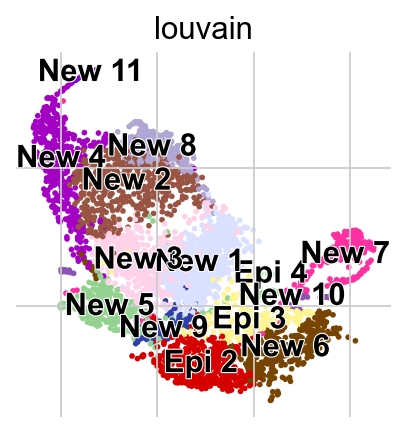

In [26]:
scv.pl.umap(adata_1)

In [27]:
scv.pp.filter_genes(adata_1, min_shared_counts=20)
scv.pp.normalize_per_cell(adata_1)
scv.pp.filter_genes_dispersion(adata_1, n_top_genes=2000)
scv.pp.log1p(adata_1)

Filtered out 23908 genes that are detected 20 counts (shared).
Normalized count data: spliced, unspliced.
Extracted 2000 highly variable genes.


In [28]:
scv.tl.recover_dynamics(adata_1, n_jobs=40)
scv.tl.velocity(adata_1, mode='dynamical')
scv.tl.velocity_graph(adata_1)

recovering dynamics (using 40/40 cores)


  0%|          | 0/2000 [00:00<?, ?gene/s]

    finished (0:01:16) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities
    finished (0:00:13) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/40 cores)


  0%|          | 0/4608 [00:00<?, ?cells/s]

    finished (0:00:18) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:01) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


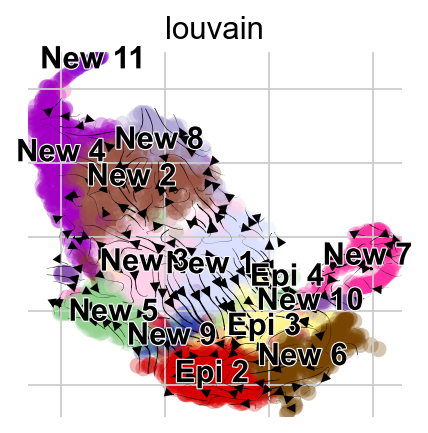

In [29]:
scv.pl.velocity_embedding_stream(adata_1, basis='X_umap') #neighbor 10, pca 50

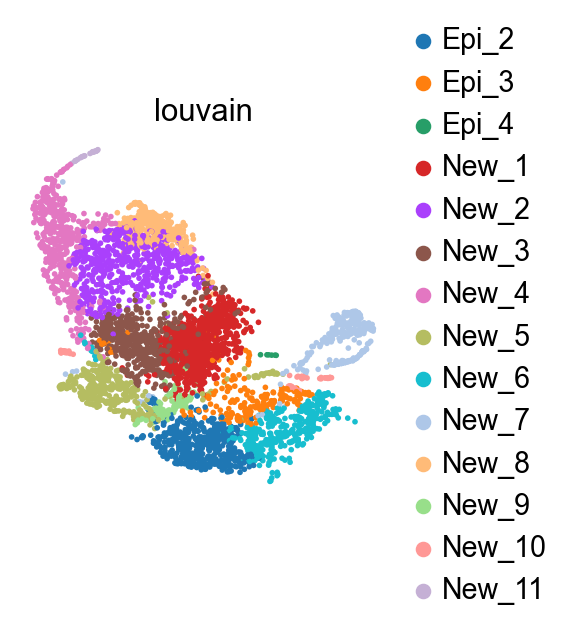

In [30]:
sc.pl.umap(CIS, color=['louvain'])

In [31]:
raw.obs['louvain'] = adata_1.obs['louvain']

In [32]:
raw.obs['louvain']

AAAGCAAGTGCTTCTC    New_1
AAATGCCTCCGCAGTG    New_9
AACGTTGGTGGTACAG      NaN
AAAGATGGTAAGGATT      NaN
AACGTTGTCTGATACG    New_5
                    ...  
TTTGGTTAGTGAACGC    New_3
TTTGTCAGTCTTCGTC    Epi_2
TTTGCGCCAAGAAGAG    New_6
TTTGGTTAGGCATGGT      NaN
TTTGTCACATAAAGGT    Epi_2
Name: louvain, Length: 7165, dtype: category
Categories (14, object): ['Epi_2', 'Epi_3', 'Epi_4', 'New_1', ..., 'New_8', 'New_9', 'New_10', 'New_11']

In [33]:
raw

AnnData object with n_obs × n_vars = 7165 × 32285
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'

In [34]:
adata=raw[raw.obs['louvain'].isin(['Epi_2','Epi_3','Epi_4','New_1','New_2','New_3','New_4','New_5','New_6',
                                  'New_7','New_8','New_9','New_10','New_11'])]
adata

View of AnnData object with n_obs × n_vars = 4608 × 32285
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'

In [35]:
adata.write('CIS_cluster_matched.h5ad', compression='gzip')  # `compression='gzip'` saves disk space, but slows down writing and subsequent reading

In [38]:
#adata = sc.read('/Users/bkim6/Desktop/KP/PCN/PCN_cluster_matched.h5ad')

normalizing counts per cell
    finished (0:00:00)


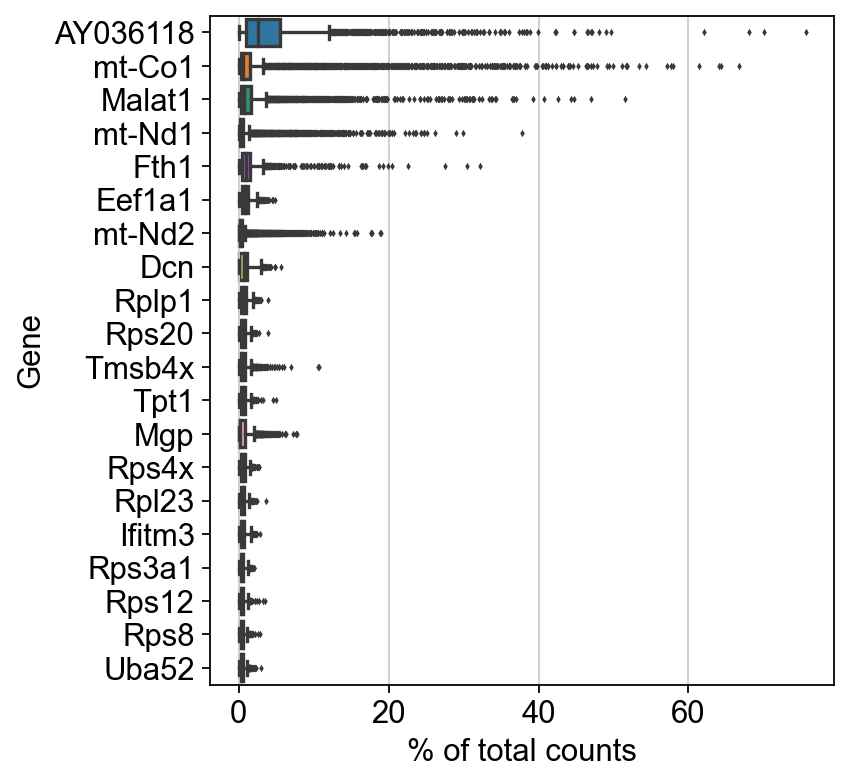

filtered out 498 cells that have less than 200 genes expressed
filtered out 15804 genes that are detected in less than 3 cells


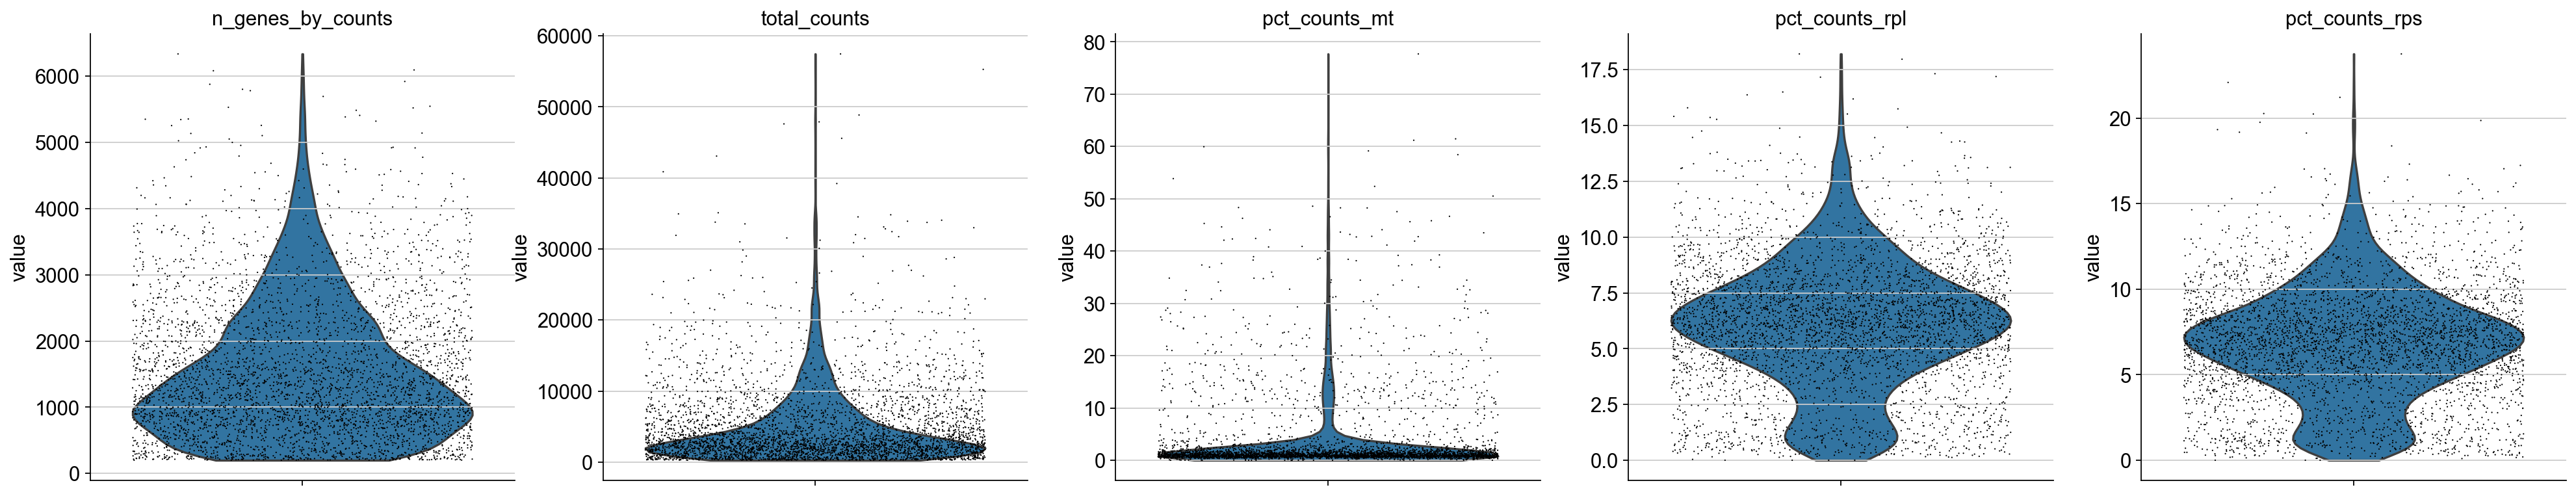

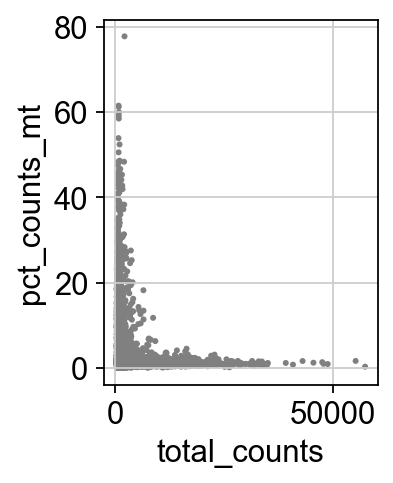

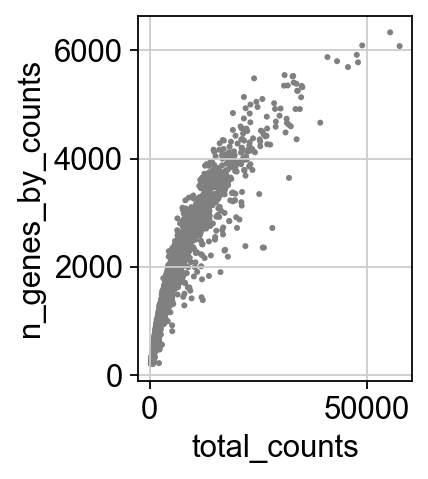

In [36]:
sc.pl.highest_expr_genes(adata, n_top=20)
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)
adata.var['mt'] = adata.var_names.str.startswith('mt-')  # annotate the group of mitochondrial genes as 'mt'
adata.var['rpl'] = adata.var_names.str.startswith('Rpl')
adata.var['rps'] = adata.var_names.str.startswith('Rps')


sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','rpl','rps'], percent_top=None, log1p=False, inplace=True)
sc.pl.violin(adata, keys=['n_genes_by_counts', 'total_counts', 'pct_counts_mt','pct_counts_rpl','pct_counts_rps'], jitter=0.4, multi_panel=True)

sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt')
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts')

adata = adata[adata.obs.n_genes_by_counts < 2500, :]
adata = adata[adata.obs.pct_counts_mt < 5, :]
adata = adata[adata.obs.pct_counts_rpl < 50, :]
adata = adata[adata.obs.pct_counts_rps < 50, :]



In [37]:
adata.write('Normal_cluster_matched_1.h5ad', compression='gzip')

In [38]:
# Output the basic filtered expression matrix to f_loom_path_scenic
row_attrs = {"Gene": np.array(adata.var_names)}
col_attrs = {"CellID": np.array(adata.obs_names), "nGene": np.array(np.sum(adata.X.transpose()>0, axis=0)).flatten(),
             "nUMI": np.array(np.sum(adata.X.transpose(), axis=0)).flatten()}
lp.create(f_loom_path_scenic, adata.X.transpose(), row_attrs, col_attrs)
# key step, after basic filtering, save into f_loom_path_scenic instead of the data after Scanpy proceedingfor SCENIC 

In [39]:
sc.pp.normalize_total(adata, target_sum=1e4)

normalizing counts per cell
    finished (0:00:00)


In [40]:
sc.pp.log1p(adata)

In [41]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


In [42]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


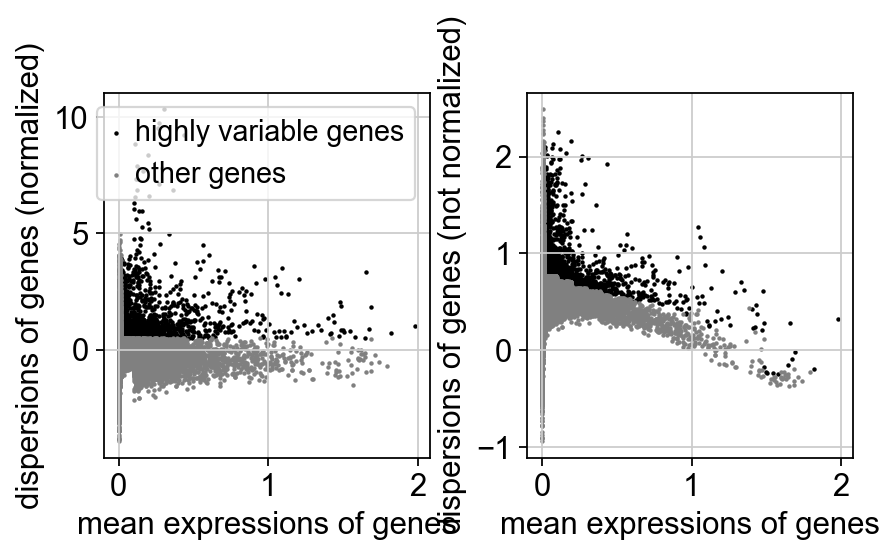

In [43]:
sc.pl.highly_variable_genes(adata)

2528
regressing out ['pct_counts_mt', 'pct_counts_rpl', 'pct_counts_rps']
    sparse input is densified and may lead to high memory use
    finished (0:00:32)
computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:03)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:07)


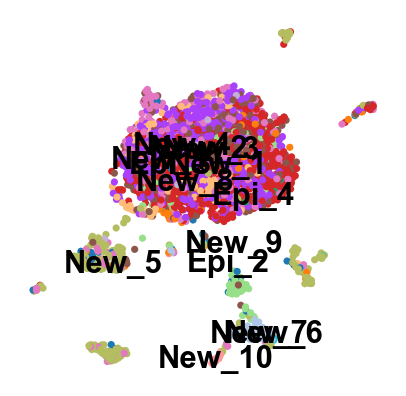

In [44]:
print(sum(adata.var.highly_variable))
adata.raw=adata
adata = adata[:, adata.var.highly_variable]
sc.pp.regress_out(adata, keys=['pct_counts_mt','pct_counts_rpl','pct_counts_rps'], n_jobs=16)
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, svd_solver='arpack')
sc.pp.neighbors(adata, n_pcs=50, knn=True)
sc.tl.umap(adata)
sc.pl.umap(adata, color=['louvain'], legend_loc='on data', frameon=False, title='', use_raw=False)

In [45]:
adata.uns['louvain_colors']

['#1f77b4',
 '#ff7f0e',
 '#279e68',
 '#d62728',
 '#aa40fc',
 '#8c564b',
 '#e377c2',
 '#b5bd61',
 '#17becf',
 '#aec7e8',
 '#ffbb78',
 '#98df8a',
 '#ff9896',
 '#c5b0d5']

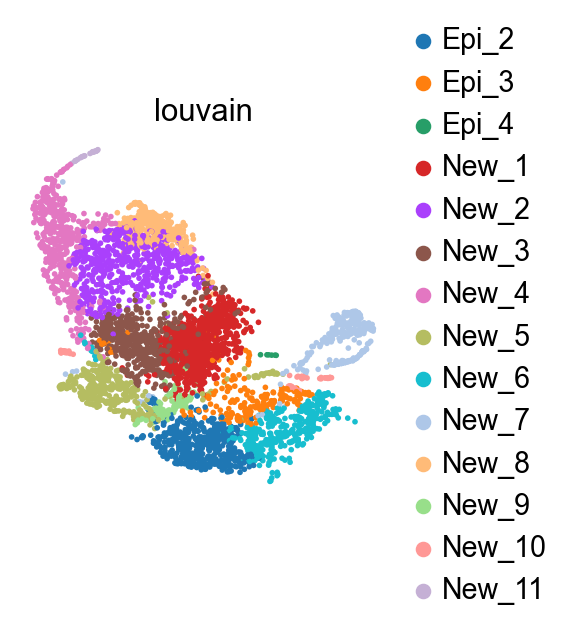

In [47]:
sc.pl.umap(CIS, color=['louvain'])

In [48]:
CIS.uns['louvain_colors']

['#1f77b4',
 '#ff7f0e',
 '#279e68',
 '#d62728',
 '#aa40fc',
 '#8c564b',
 '#e377c2',
 '#b5bd61',
 '#17becf',
 '#aec7e8',
 '#ffbb78',
 '#98df8a',
 '#ff9896',
 '#c5b0d5']

In [49]:
adata.uns['louvain_colors']= ['#0b03ff', '#04B3F5', '#1a5d9c', 
                              '#424EDD', '#0574a1', 
                              '#ffbdde','#d14d4d',
                              '#43FFE5', 
                              '#c705fa', '#672578', '#f01abf', '#d389e8','#7024ad', '#e603ff']
                                                                                 
adata.uns['louvain_colors']

['#0b03ff',
 '#04B3F5',
 '#1a5d9c',
 '#424EDD',
 '#0574a1',
 '#ffbdde',
 '#d14d4d',
 '#43FFE5',
 '#c705fa',
 '#672578',
 '#f01abf',
 '#d389e8',
 '#7024ad',
 '#e603ff']

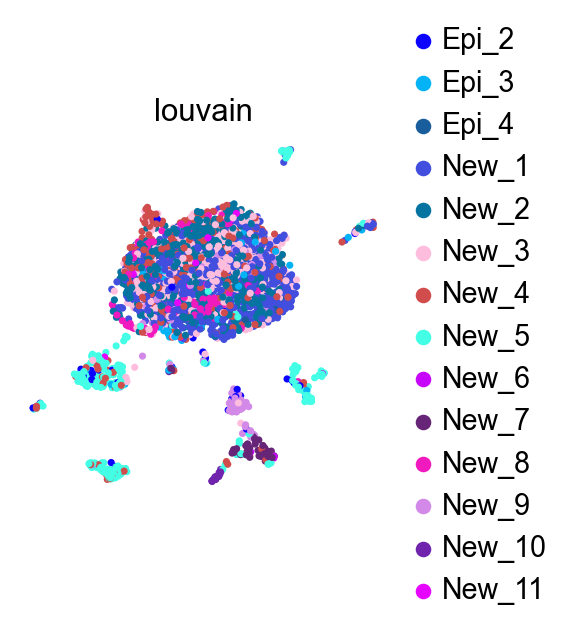

In [50]:
sc.pl.umap(adata, color='louvain', legend_loc='right margin')

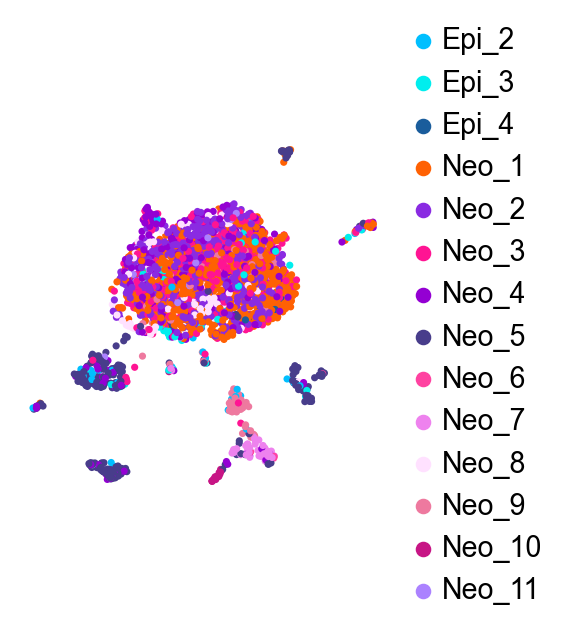

In [55]:
# create adata.obs['pca_louvain'] to store louvain cluster names determined by pca, because later aucell based embedding will cover adata.obs['louvain']
adata.obs['pca_louvain'] = (
    adata.obs['louvain']
    .map(lambda x: {'Epi_2': 'Epi_2', 'Epi_3': 'Epi_3', 'Epi_4':'Epi_4',
                    
                    'New_1':'Neo_1','New_2':'Neo_2',
                    'New_3':'Neo_3','New_4':'Neo_4', 
                    'New_5': 'Neo_5','New_6':'Neo_6',
                    'New_7':'Neo_7','New_8':'Neo_8', 
                    'New_9': 'Neo_9','New_10':'Neo_10',
                   'New_11': 'Neo_11'
                   }.get(x, x))
    .astype("category")
)
adata.obs['pca_louvain'].cat.reorder_categories([ 'Epi_2' ,
                    'Epi_3','Epi_4','Neo_1','Neo_2',
                    'Neo_3','Neo_4', 
                    'Neo_5','Neo_6','Neo_7','Neo_8',
                    'Neo_9','Neo_10', 
                    'Neo_11'], inplace = True)
sc.pl.umap(adata, color=['pca_louvain'], legend_loc='right margin', title='', frameon=False, use_raw=False,
           palette={'Epi_2': '#00BFFF', 'Epi_3': '#00EEEE', 'Epi_4':'#1a5d9c',
               'Neo_1':'#FF6103','Neo_2':'#8A2BE2',
                    'Neo_3':'#FF1493','Neo_4':'#9400D3', 
                    'Neo_5': '#483D8B','Neo_6':'#ff42a1',
                    'Neo_7':'#EE82EE','Neo_8':'#FFE1FF', 
                    'Neo_9': '#EE799F','Neo_10':'#C71585',
                   'Neo_11': '#AB82FF'})


In [56]:
adata    # there will generate adata.uns['pca_louvain_colors']

AnnData object with n_obs × n_vars = 2888 × 2528
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_louvain'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'louvain_colors', 'pca_louvain_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'

In [55]:
# STEP 1: Gene regulatory network inference, and module generation

In [58]:
%%time
!pyscenic grn {f_loom_path_scenic} {Mouse_TFS_FNAME} -o {ADJACENCIES_FNAME} --num_workers 16

preparing dask client
parsing input
creating dask graph
16 partitions
computing dask graph
not shutting down client, client was created externally
finished
CPU times: total: 641 ms
Wall time: 50min 36s



2022-05-09 09:24:17,611 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2022-05-09 09:24:18,926 - pyscenic.cli.pyscenic - INFO - Inferring regulatory networks.
C:\Users\KKo1\Anaconda3\envs\py38_pyscenic\lib\contextlib.py:120: UserWarning: Creating scratch directories is taking a surprisingly long time. This is often due to running workers on a network file system. Consider specifying a local-directory to point workers to write scratch data to a local disk.
  next(self.gen)
C:\Users\KKo1\Anaconda3\envs\py38_pyscenic\lib\site-packages\distributed\node.py:177: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 54052 instead
  warnings.warn(
2022-05-09 10:13:43,564 - distributed.nanny - WARNING - Worker process still alive after 3.999997901916504 seconds, killing

2022-05-09 10:13:44,792 - pyscenic.cli.pyscenic - INFO - Writing results to file.


In [57]:
# STEP 2-3: Motif enrichment and TF-regulon prediction

In [59]:
DBS_PARAM = ' '.join(RANKING_DBS_FNAMES)

In [60]:
%%time
!pyscenic ctx {ADJACENCIES_FNAME} {DBS_PARAM} \
            --annotations_fname {MOTIF_ANNOTATIONS_FNAME} \
            --expression_mtx_fname {f_loom_path_scenic} \
            --output {MOTIFS_FNAME} \
            --num_workers 16
# The results is a list of enriched motifs for the modules

CPU times: total: 594 ms
Wall time: 51min 15s



2022-05-09 10:14:54,948 - pyscenic.cli.pyscenic - INFO - Creating modules.

2022-05-09 10:14:58,151 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2022-05-09 10:14:59,995 - pyscenic.utils - INFO - Calculating Pearson correlations.

2022-05-09 10:15:02,010 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].

2022-05-09 10:16:41,939 - pyscenic.utils - INFO - Creating modules.

2022-05-09 10:22:17,803 - pyscenic.cli.pyscenic - I


[                                        ] | 0% Completed |  0.0s
[                                        ] | 0% Completed |  0.1s
[                                        ] | 0% Completed |  0.3s
[                                        ] | 0% Completed |  0.4s
[                                        ] | 0% Completed |  0.6s
[                                        ] | 0% Completed |  1.0s
[                                        ] | 0% Completed |  1.2s
[                                        ] | 0% Completed |  1.3s
[                                        ] | 0% Completed |  1.4s
[                                        ] | 0% Completed |  1.6s
[                                        ] | 0% Completed |  2.0s
[                                        ] | 0% Completed |  2.1s
[                                        ] | 0% Completed |  2.3s
[                                        ] | 0% Completed |  2.4s
[                                        ] | 0% Completed |  2.9s
[        



2022-05-09 10:25:12,851 - pyscenic.transform - WARNING - Less than 80% of the genes in Zxdc could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:25:25,256 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp94 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:25:28,459 - pyscenic.transform - WARNING - Less than 80% of the genes in Atf7 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:25:29,693 - pyscenic.transform - WARNING - Less than 80% of the genes in Bach2 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:25:30,131 - pyscenic.transform - WARNING - Less than 80% of the genes in Banp could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:25:31,224 - pyscenic.transform - WARNING - Less

In [ ]:
# Column name	Description
# TF	Transcription Factor (TF) for which an enriched motif is discovered.
# motifID	The identifier of the enriched motif.
# AUC	Area Under the recovery Curve statistic for this enriched motif.
# NES	Normalized Enrichment Score for this enriched motif.
# Context	Collection of tags clarifying the origin of the module for this factor: e.g. ranking database, ...
# Annotation	Verbose description of the annotation available for this motif.
# MotifSimilarityQvalue	The TomTom derived Q-value for motif similarity (if used for assigning the factor to this enriched motif).
# OrthologousIdentity	The Amino Acid Identity between factors (if used for assigning the factor to this enriched motif).
# RankAtMax	The position of the Leading Edge which is used as a threshold on the whole genome ranking of the motif to decide if a gene in the input is a direct target of a TF that binds this motif.
# TargetGenes	A list of pairs: genes and their associated weights from GRNBoost2.

In [61]:
%%time
df_motifs = load_motifs(MOTIFS_FNAME)

[                                        ] | 0% Completed |  1min  6.4s
[                                        ] | 0% Completed |  1min  6.5s
[                                        ] | 0% Completed |  1min  7.2s
[                                        ] | 0% Completed |  1min  7.3s
[                                        ] | 0% Completed |  1min  7.5s
[                                        ] | 0% Completed |  1min  8.0s
[                                        ] | 0% Completed |  1min  8.1s
[                                        ] | 0% Completed |  1min  8.3s
[                                        ] | 0% Completed |  1min  8.9s
[                                        ] | 0% Completed |  1min  9.0s
[                                        ] | 0% Completed |  1min  9.7s
[                                        ] | 0% Completed |  1min 10.1s
[                                        ] | 0% Completed |  1min 10.3s
[                                        ] | 0% Completed |  1mi


2022-05-09 10:39:10,236 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp442 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:39:11,202 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp449 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:39:13,125 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp507 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:39:13,344 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp513 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:39:13,691 - pyscenic.transform - WARNING - Less than 80% of the genes in Zfp516 could be mapped to mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr. Skipping this module.

2022-05-09 10:39:17,570 - pyscenic.transform - WARNING


[                                        ] | 0% Completed |  2min 58.7s
[                                        ] | 0% Completed |  2min 58.8s
[                                        ] | 0% Completed |  2min 58.9s
[                                        ] | 0% Completed |  2min 59.1s
[                                        ] | 0% Completed |  2min 59.2s
[                                        ] | 0% Completed |  2min 59.3s
[                                        ] | 0% Completed |  2min 59.4s
[                                        ] | 0% Completed |  2min 59.5s
[                                        ] | 0% Completed |  2min 59.7s
[                                        ] | 0% Completed |  2min 59.8s
[                                        ] | 0% Completed |  2min 59.9s
[                                        ] | 0% Completed |  2min 60.0s
[                                        ] | 0% Completed |  3min  0.1s
[                                        ] | 0% Completed |  3m

In [62]:
df_motifs.head()

[######################################  ] | 95% Completed | 42min 30.2s
[######################################  ] | 95% Completed | 42min 30.3s
[######################################  ] | 95% Completed | 42min 30.4s
[######################################  ] | 95% Completed | 42min 30.5s
[######################################  ] | 95% Completed | 42min 30.6s
[######################################  ] | 95% Completed | 42min 30.8s
[######################################  ] | 95% Completed | 42min 30.9s
[######################################  ] | 95% Completed | 42min 31.0s
[######################################  ] | 95% Completed | 42min 31.1s
[######################################  ] | 95% Completed | 42min 31.2s
[######################################  ] | 95% Completed | 42min 31.3s
[######################################  ] | 95% Completed | 42min 31.4s
[######################################  ] | 95% Completed | 42min 31.5s
[######################################  ] | 95% Co

Enrichment            \
                                                  AUC       NES   
TF     MotifID                                                    
Arntl2 swissregulon__hs__bHLH_family.p2      0.059811  3.615805   
Atf1   dbcorrdb__RCOR1__ENCSR000ECM_1__m1    0.051533  3.019337   
Atf2   cisbp__M0297                          0.050525  3.374672   
Atf3   dbcorrdb__POLR2A__ENCSR000BGD_1__m1   0.055080  3.001788   
       dbcorrdb__TAF1__ENCSR000BIM_1__m1     0.055820  3.112587   

                                                                  \
                                           MotifSimilarityQvalue   
TF     MotifID                                                     
Arntl2 swissregulon__hs__bHLH_family.p2                 0.000000   
Atf1   dbcorrdb__RCOR1__ENCSR000ECM_1__m1               0.000070   
Atf2   cisbp__M0297                                     0.000207   
Atf3   dbcorrdb__POLR2A__ENCSR000BGD_1__m1              0.000018   
       dbcorrdb__TAF1__ENCSR000BIM_1__m1                0.000002   

                                                                \
                                           OrthologousIdentity   
TF     MotifID                                                   
Arntl2 swissregulon__hs__bHLH_family.p2               0.720207   
Atf1   dbcorrdb__RCOR1__ENCSR000ECM_1__m1             0.911439   
Atf2   cisbp__M0297                                   1.000000   
Atf3   dbcorrdb__POLR2A__ENCSR000BGD_1__m1            0.950276   
       dbcorrdb__TAF1__ENCSR000BIM_1__m1              0.950276   

                                                                                               \
                                                                                   Annotation   
TF     MotifID                                                                                  
Arntl2 swissregulon__hs__bHLH_family.p2     gene is orthologous to ENSG00000029153 in H. s...   
Atf1   dbcorrdb__RCOR1__ENCSR000ECM_1__m1   motif similar to dbcorrdb__ATF1__ENCSR000DNZ_1...   
Atf2   cisbp__M0297                         gene is annotated for similar motif cisbp__M03...   
Atf3   dbcorrdb__POLR2A__ENCSR000BGD_1__m1  motif similar to dbcorrdb__ATF3__ENCSR000BKC_1...   
       dbcorrdb__TAF1__ENCSR000BIM_1__m1    motif similar to dbcorrdb__ATF3__ENCSR000BKC_1...   

                                                                                               \
                                                                                      Context   
TF     MotifID                                                                                  
Arntl2 swissregulon__hs__bHLH_family.p2     (weight>75.0%, mm10__refseq-r80__10kb_up_and_d...   
Atf1   dbcorrdb__RCOR1__ENCSR000ECM_1__m1   (weight>75.0%, mm10__refseq-r80__10kb_up_and_d...   
Atf2   cisbp__M0297                         (weight>75.0%, mm10__refseq-r80__10kb_up_and_d...   
Atf3   dbcorrdb__POLR2A__ENCSR000BGD_1__m1  (weight>75.0%, mm10__refseq-r80__10kb_up_and_d...   
       dbcorrdb__TAF1__ENCSR000BIM_1__m1    (weight>75.0%, mm10__refseq-r80__10kb_up_and_d...   

                                                                                               \
                                                                                  TargetGenes   
TF     MotifID                                                                                  
Arntl2 swissregulon__hs__bHLH_family.p2     [(Pa2g4, 0.6680240083778224), (Cacng4, 0.56989...   
Atf1   dbcorrdb__RCOR1__ENCSR000ECM_1__m1   [(Adgrg1, 0.9949112438237228), (Bmp1, 0.543870...   
Atf2   cisbp__M0297                         [(Gtpbp1, 0.4574345205713408), (Hic1, 0.971892...   
Atf3   dbcorrdb__POLR2A__ENCSR000BGD_1__m1  [(Cnot3, 0.7163612984132195), (Son, 1.77777071...   
       dbcorrdb__TAF1__ENCSR000BIM_1__m1    [(Cnot3, 0.7163612984132195), (Tra2b, 0.829411...   

                                                      
                                           Ran

In [63]:
display_logos(df_motifs.head())

In [ ]:
# STEP 4: Cellular enrichment

In [64]:
# REGULON CREATION
def derive_regulons(motifs, db_names=('mm10__refseq-r80__10kb_up_and_down_tss.mc9nr', 'mm10__refseq-r80__500bp_up_and_100bp_down_tss.mc9nr')):
    motifs.columns = motifs.columns.droplevel(0)

    def contains(*elems):
        def f(context):
            return any(elem in context for elem in elems)
        return f

    # We remove the enriched motifs for the modules that were created using the method 'weight>50.0%'
    # because these modules are not part of the default settings of modules_from_adjacencies anymore
    motifs = motifs[
        np.fromiter(map(compose(op.not_, contains('weight>50.0%')), motifs.Context), dtype=np.bool) & \
        np.fromiter(map(contains(*db_names), motifs.Context), dtype=np.bool) & \
        np.fromiter(map(contains('activating'), motifs.Context), dtype=np.bool)]

    # We build regulons only using enriched motifs with a NES of 3.0 or higher; we take only directly annotated TFs or TF annotated
    # for an orthologous gene into account; and we only keep regulons with at least 10 genes.
    regulons = list(filter(lambda r: len(r) >= 10, df2regulons(motifs[(motifs['NES'] >= 3.0) 
                                                                      & ((motifs['Annotation'] == 'gene is directly annotated')
                                                                         | (motifs['Annotation'].str.startswith('gene is orthologous to')
                                                                            & motifs['Annotation'].str.endswith('which is directly annotated for motif')))
                                                                     ])))
    
    # Rename regulons, i.e. remove suffix.
    return list(map(lambda r: r.rename(r.transcription_factor), regulons))

In [65]:
regulons = derive_regulons(df_motifs)

Create regulons from a dataframe of enriched features.
Additional columns saved: []


In [66]:
# Pickle these regulons.
with open(REGULONS_DAT_FNAME, 'wb') as f:
    pickle.dump(regulons, f)

In [67]:
# AUCELL
nGenesDetectedPerCellbefore = np.sum(adata.X>0, axis=1)
nGenesDetectedPerCell = pd.Series(nGenesDetectedPerCellbefore)
percentiles = nGenesDetectedPerCell.quantile(q=[0.01, 0.05, 0.10, 0.50, 1])
percentiles

0.01    100.0
0.05    144.0
0.10    167.0
0.50    276.5
1.00    967.0
dtype: float64

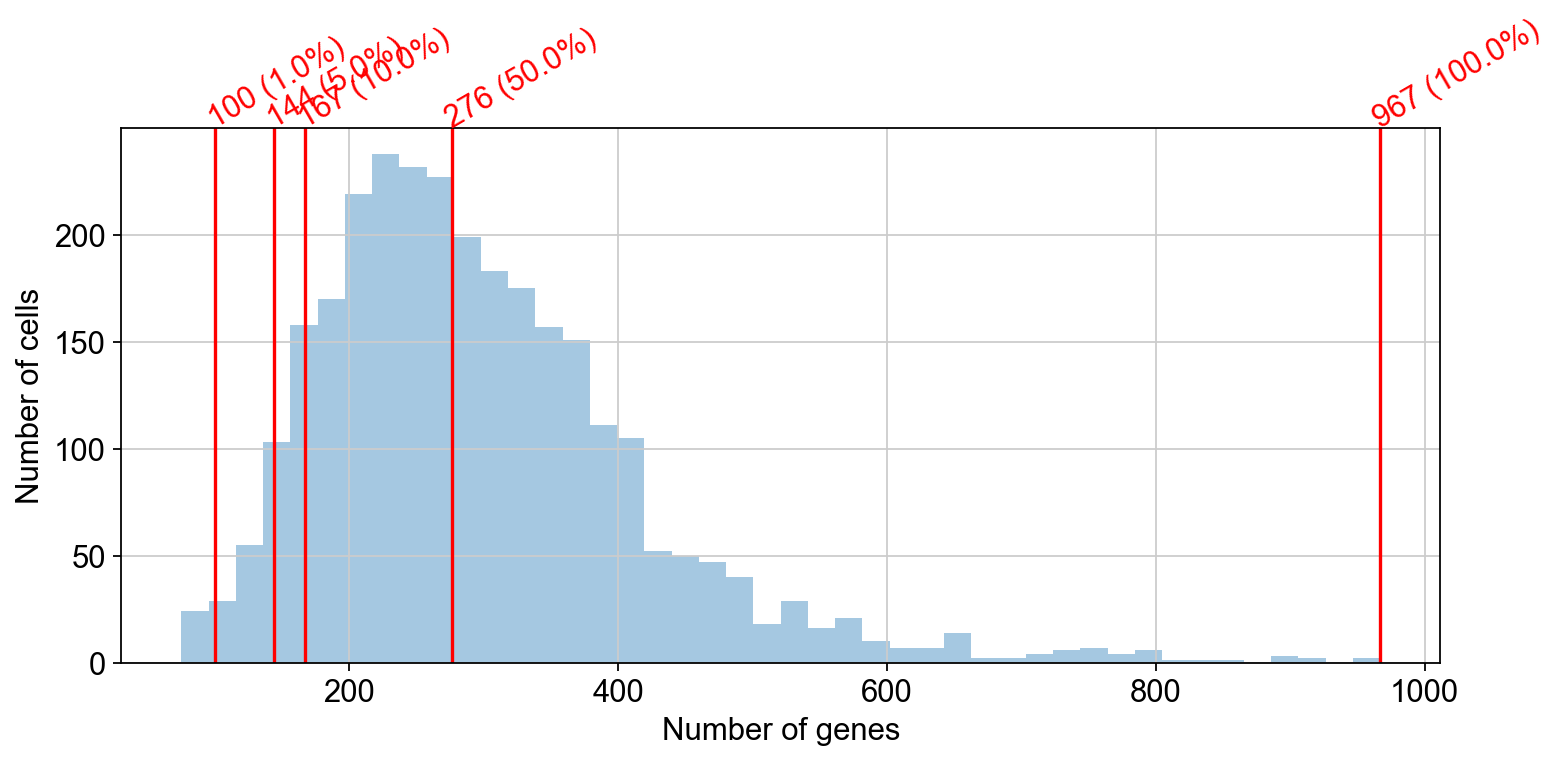

In [68]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
sns.distplot(nGenesDetectedPerCell, norm_hist=False, kde=False, bins='fd')
for i,x in enumerate(percentiles):
    fig.gca().axvline(x=x, ymin=0, ymax=1, color='red')
    ax.text(x=x, y=ax.get_ylim()[1], s=f'{int(x)} ({percentiles.index.values[i]*100}%)', color='red', rotation=30, size='medium', rotation_mode='anchor')
ax.set_xlabel('Number of genes')
ax.set_ylabel('Number of cells')
plt.tight_layout()

In [69]:
%%time
!pyscenic aucell \
    {f_loom_path_scenic} \
    {REGULONS_DAT_FNAME} \
    --output {AUCELL_MTX_FNAME} \
    --num_workers 16

CPU times: total: 0 ns
Wall time: 2min 18s



2022-05-09 11:06:39,092 - pyscenic.cli.pyscenic - INFO - Loading expression matrix.

2022-05-09 11:06:40,325 - pyscenic.cli.pyscenic - INFO - Loading gene signatures.

2022-05-09 11:06:40,341 - pyscenic.cli.pyscenic - INFO - Calculating cellular enrichment.

2022-05-09 11:08:16,310 - pyscenic.cli.pyscenic - INFO - Writing results to file.


In [70]:
auc_mtx = pd.read_csv(AUCELL_MTX_FNAME, index_col=0)
auc_mtx

,Arnt,Arnt2,Arntl2,Atf1,Atf3,Atf4,Atf6,Bcl11a,Bcl3,Bhlhe40,...,Zfp128,Zfp217,Zfp362,Zfp46,Zfp560,Zfp575,Zfp64,Zfp647,Zfp672,Zscan21
Cell,,,,,,,,,,,,,,,,,,,,,
AAAGCAAGTGCTTCTC,0.008879,0.000000,0.005383,0.025007,0.036022,0.033404,0.043787,0.040200,0.032592,0.000000,...,0.028193,0.017631,0.023379,0.022838,0.0,0.057767,0.071400,0.000383,0.081183,0.000000
AAATGCCTCCGCAGTG,0.015024,0.000000,0.033234,0.032473,0.071023,0.054414,0.033388,0.052109,0.035951,0.008647,...,0.000000,0.038835,0.031946,0.038835,0.0,0.008576,0.000000,0.000000,0.000000,0.000000
AACGTTGTCTGATACG,0.025608,0.000000,0.008464,0.026662,0.027251,0.045228,0.090761,0.034436,0.049465,0.000000,...,0.024972,0.003978,0.005069,0.107568,0.0,0.042799,0.032261,0.000000,0.062404,0.000000
AACACGTCAAGCGATG,0.013565,0.000000,0.045432,0.027618,0.073367,0.054537,0.032369,0.000000,0.037621,0.006144,...,0.000000,0.054072,0.024914,0.031664,0.0,0.003317,0.000000,0.000000,0.087251,0.000000
AAACGGGTCAGCATGT,0.021353,0.000000,0.000000,0.025228,0.255820,0.081845,0.046943,0.058556,0.059533,0.041262,...,0.008145,0.039273,0.032696,0.094881,0.0,0.095874,0.036913,0.000000,0.050332,0.082767
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCAAGCCTCGTG,0.025132,0.000000,0.009740,0.017027,0.140363,0.054000,0.071361,0.049302,0.063782,0.043310,...,0.023595,0.000000,0.041905,0.562776,0.0,0.096683,0.010316,0.000000,0.092936,0.087379
TTTGCGCGTTCGAATC,0.017943,0.000000,0.021845,0.042880,0.139315,0.073424,0.104732,0.000000,0.108849,0.013539,...,0.008705,0.174454,0.005390,0.180494,0.0,0.000000,0.000000,0.000000,0.174182,0.137379
TTTGCGCAGTACCGGA,0.018096,0.000000,0.017208,0.069616,0.158732,0.087216,0.186203,0.070312,0.105736,0.000000,...,0.000000,0.245314,0.061286,0.089144,0.0,0.054531,0.000000,0.000000,0.189512,0.071117


In [ ]:
# STEP 5 - Regulon activity binarization

In [71]:
%%time
binary_mtx, thresholds = binarize(auc_mtx)
binary_mtx.to_csv(BINARY_MTX_FNAME)
thresholds.to_frame().rename(columns={0:'threshold'}).to_csv(THR_FNAME)

CPU times: total: 281 ms
Wall time: 23min 12s


In [72]:
binary_mtx = pd.read_csv(BINARY_MTX_FNAME, index_col=0)
binary_mtx

,Arnt,Arnt2,Arntl2,Atf1,Atf3,Atf4,Atf6,Bcl11a,Bcl3,Bhlhe40,...,Zfp128,Zfp217,Zfp362,Zfp46,Zfp560,Zfp575,Zfp64,Zfp647,Zfp672,Zscan21
Cell,,,,,,,,,,,,,,,,,,,,,
AAAGCAAGTGCTTCTC,0,0,0,0,0,0,0,1,0,0,...,1,0,0,0,0,0,1,0,1,0
AAATGCCTCCGCAGTG,0,0,1,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
AACGTTGTCTGATACG,0,0,0,0,0,0,1,1,0,0,...,1,0,0,0,0,0,1,0,0,0
AACACGTCAAGCGATG,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
AAACGGGTCAGCATGT,0,0,0,0,0,0,0,1,0,1,...,0,0,0,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCAAGCCTCGTG,0,0,0,0,0,0,0,1,0,1,...,1,0,0,1,0,0,0,0,1,1
TTTGCGCGTTCGAATC,0,0,0,0,0,0,1,0,1,0,...,0,1,0,1,0,0,0,0,1,1
TTTGCGCAGTACCGGA,0,0,0,1,0,0,1,1,1,0,...,0,1,1,0,0,0,0,0,1,1


In [73]:
thresholds = pd.read_csv(THR_FNAME, index_col=0).threshold
thresholds

Arnt       0.046674
Arnt2      0.030854
Arntl2     0.023903
Atf1       0.052139
Atf3       0.306517
             ...   
Zfp575     0.107433
Zfp64      0.021108
Zfp647     0.028156
Zfp672     0.068329
Zscan21    0.029070
Name: threshold, Length: 211, dtype: float64

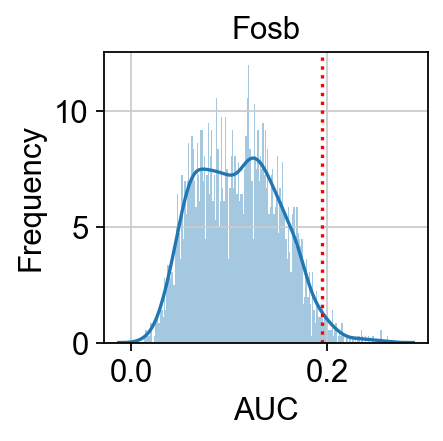

In [74]:
fig, ax = plt.subplots(1, 1)
plot_binarization(auc_mtx=auc_mtx, regulon_name='Fosb', threshold=thresholds['Fosb'])
ax.set_ylabel('Frequency')
plt.tight_layout()
savesvg('AUC_binarization - Normal - Fosb.svg', fig)

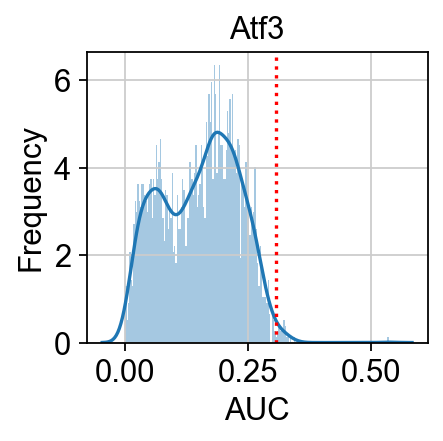

In [75]:
fig, ax = plt.subplots(1, 1)
plot_binarization(auc_mtx=auc_mtx, regulon_name='Atf3', threshold=thresholds['Atf3'])
ax.set_ylabel('Frequency')
plt.tight_layout()
savesvg('AUC_binarization - Normal - Atf3.svg', fig)

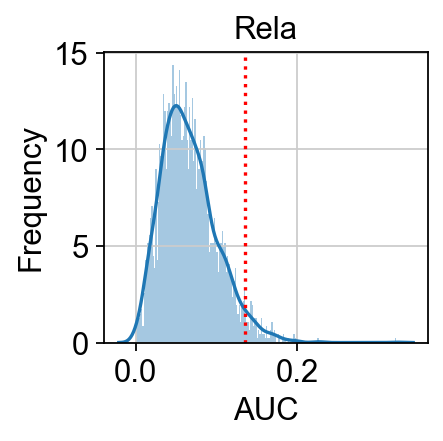

In [76]:
fig, ax = plt.subplots(1, 1)
plot_binarization(auc_mtx=auc_mtx, regulon_name='Rela', threshold=thresholds['Rela'])
ax.set_ylabel('Frequency')
plt.tight_layout()
savesvg('AUC_binarization - Normal - Rela.svg', fig)

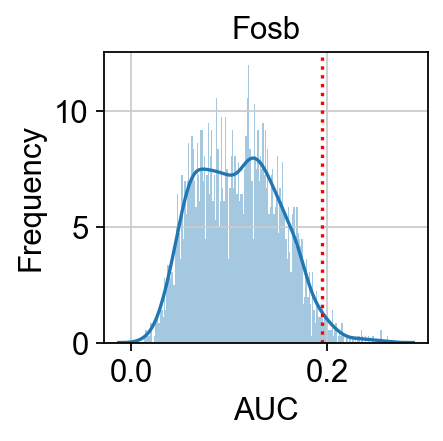

In [77]:
fig, ax = plt.subplots(1, 1)
plot_binarization(auc_mtx=auc_mtx, regulon_name='Fosb', threshold=thresholds['Fosb'])
ax.set_ylabel('Frequency')
plt.tight_layout()
savesvg('AUC_binarization - Normal - Fosb.svg', fig)

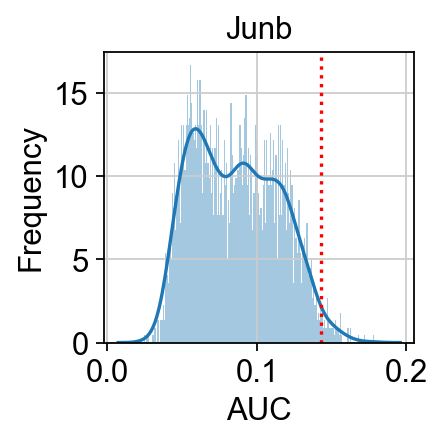

In [78]:
fig, ax = plt.subplots(1, 1)
plot_binarization(auc_mtx=auc_mtx, regulon_name='Junb', threshold=thresholds['Junb'])
ax.set_ylabel('Frequency')
plt.tight_layout()
savesvg('AUC_binarization - Normal - Junb.svg', fig)

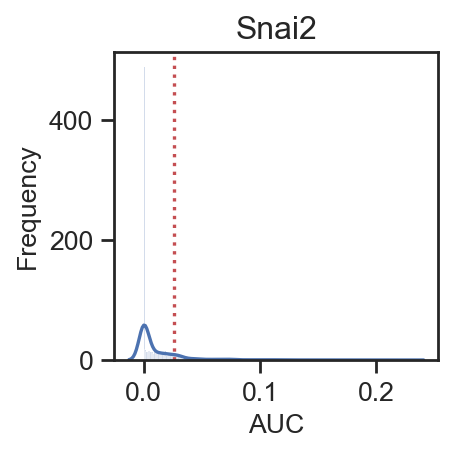

In [134]:
fig, ax = plt.subplots(1, 1)
plot_binarization(auc_mtx=auc_mtx, regulon_name='Snai2', threshold=thresholds['Snai2'])
ax.set_ylabel('Frequency')
plt.tight_layout()
savesvg('AUC_binarization - CIS - Snai2.svg', fig)

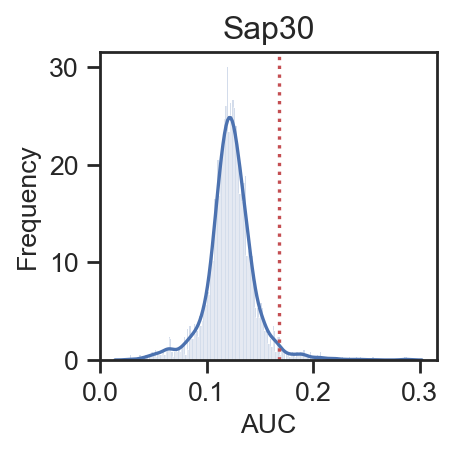

In [135]:
fig, ax = plt.subplots(1, 1)
plot_binarization(auc_mtx=auc_mtx, regulon_name='Sap30', threshold=thresholds['Sap30'])
ax.set_ylabel('Frequency')
plt.tight_layout()
savesvg('AUC_binarization - CIS - Sap30.svg', fig)

In [ ]:
# Create heatmap with binarized regulon activity

In [79]:
def palplot(pal, names, colors=None, size=1):
    n = len(pal)
    f, ax = plt.subplots(1, 1, figsize=(n * size, size))
    ax.imshow(np.arange(n).reshape(1, n),
              cmap=mpl.colors.ListedColormap(list(pal)),
              interpolation="nearest", aspect="auto")
    ax.set_xticks(np.arange(n) - 0.5)
    ax.set_yticks([-0.5, 0.5])
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    colors = n * ['k'] if colors is None else colors
    for idx, (name, color) in enumerate(zip(names, colors)):
        ax.text(0.0+idx, 0.0, name, color=color, horizontalalignment='center', verticalalignment='center')
    return f

In [80]:
adata

AnnData object with n_obs × n_vars = 2888 × 2528
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_louvain'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'louvain_colors', 'pca_louvain_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'

In [81]:
N_COLORS = len(adata.obs['pca_louvain'].dtype.categories)
COLORS = [x for x in adata.uns['pca_louvain_colors']]

In [82]:
pca_louvain_color_lut = dict(zip(adata.obs['pca_louvain'].dtype.categories, adata.uns['pca_louvain_colors']))
CellID_to_pca_louvain_lut = adata.obs['pca_louvain'].to_dict()
white_black_palette = sns.xkcd_palette(["white", "black"])

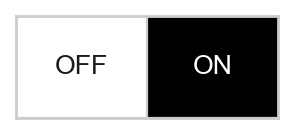

In [84]:
sns.set()
sns.set_style("whitegrid")
fig = palplot(white_black_palette, ['OFF', 'ON'], ['k', 'w'])
savesvg('legend - CIS - on_off.svg', fig)

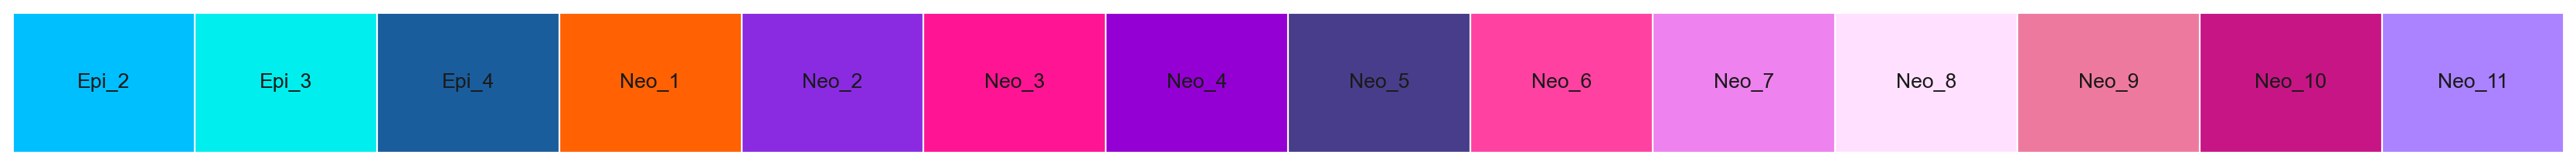

In [85]:
sns.set()
sns.set(font_scale=1)
fig = palplot(sns.color_palette(COLORS, n_colors=N_COLORS), adata.obs['pca_louvain'].dtype.categories, size=1.5)
savesvg('legend - CIS - pca_louvain_colors.svg', fig)

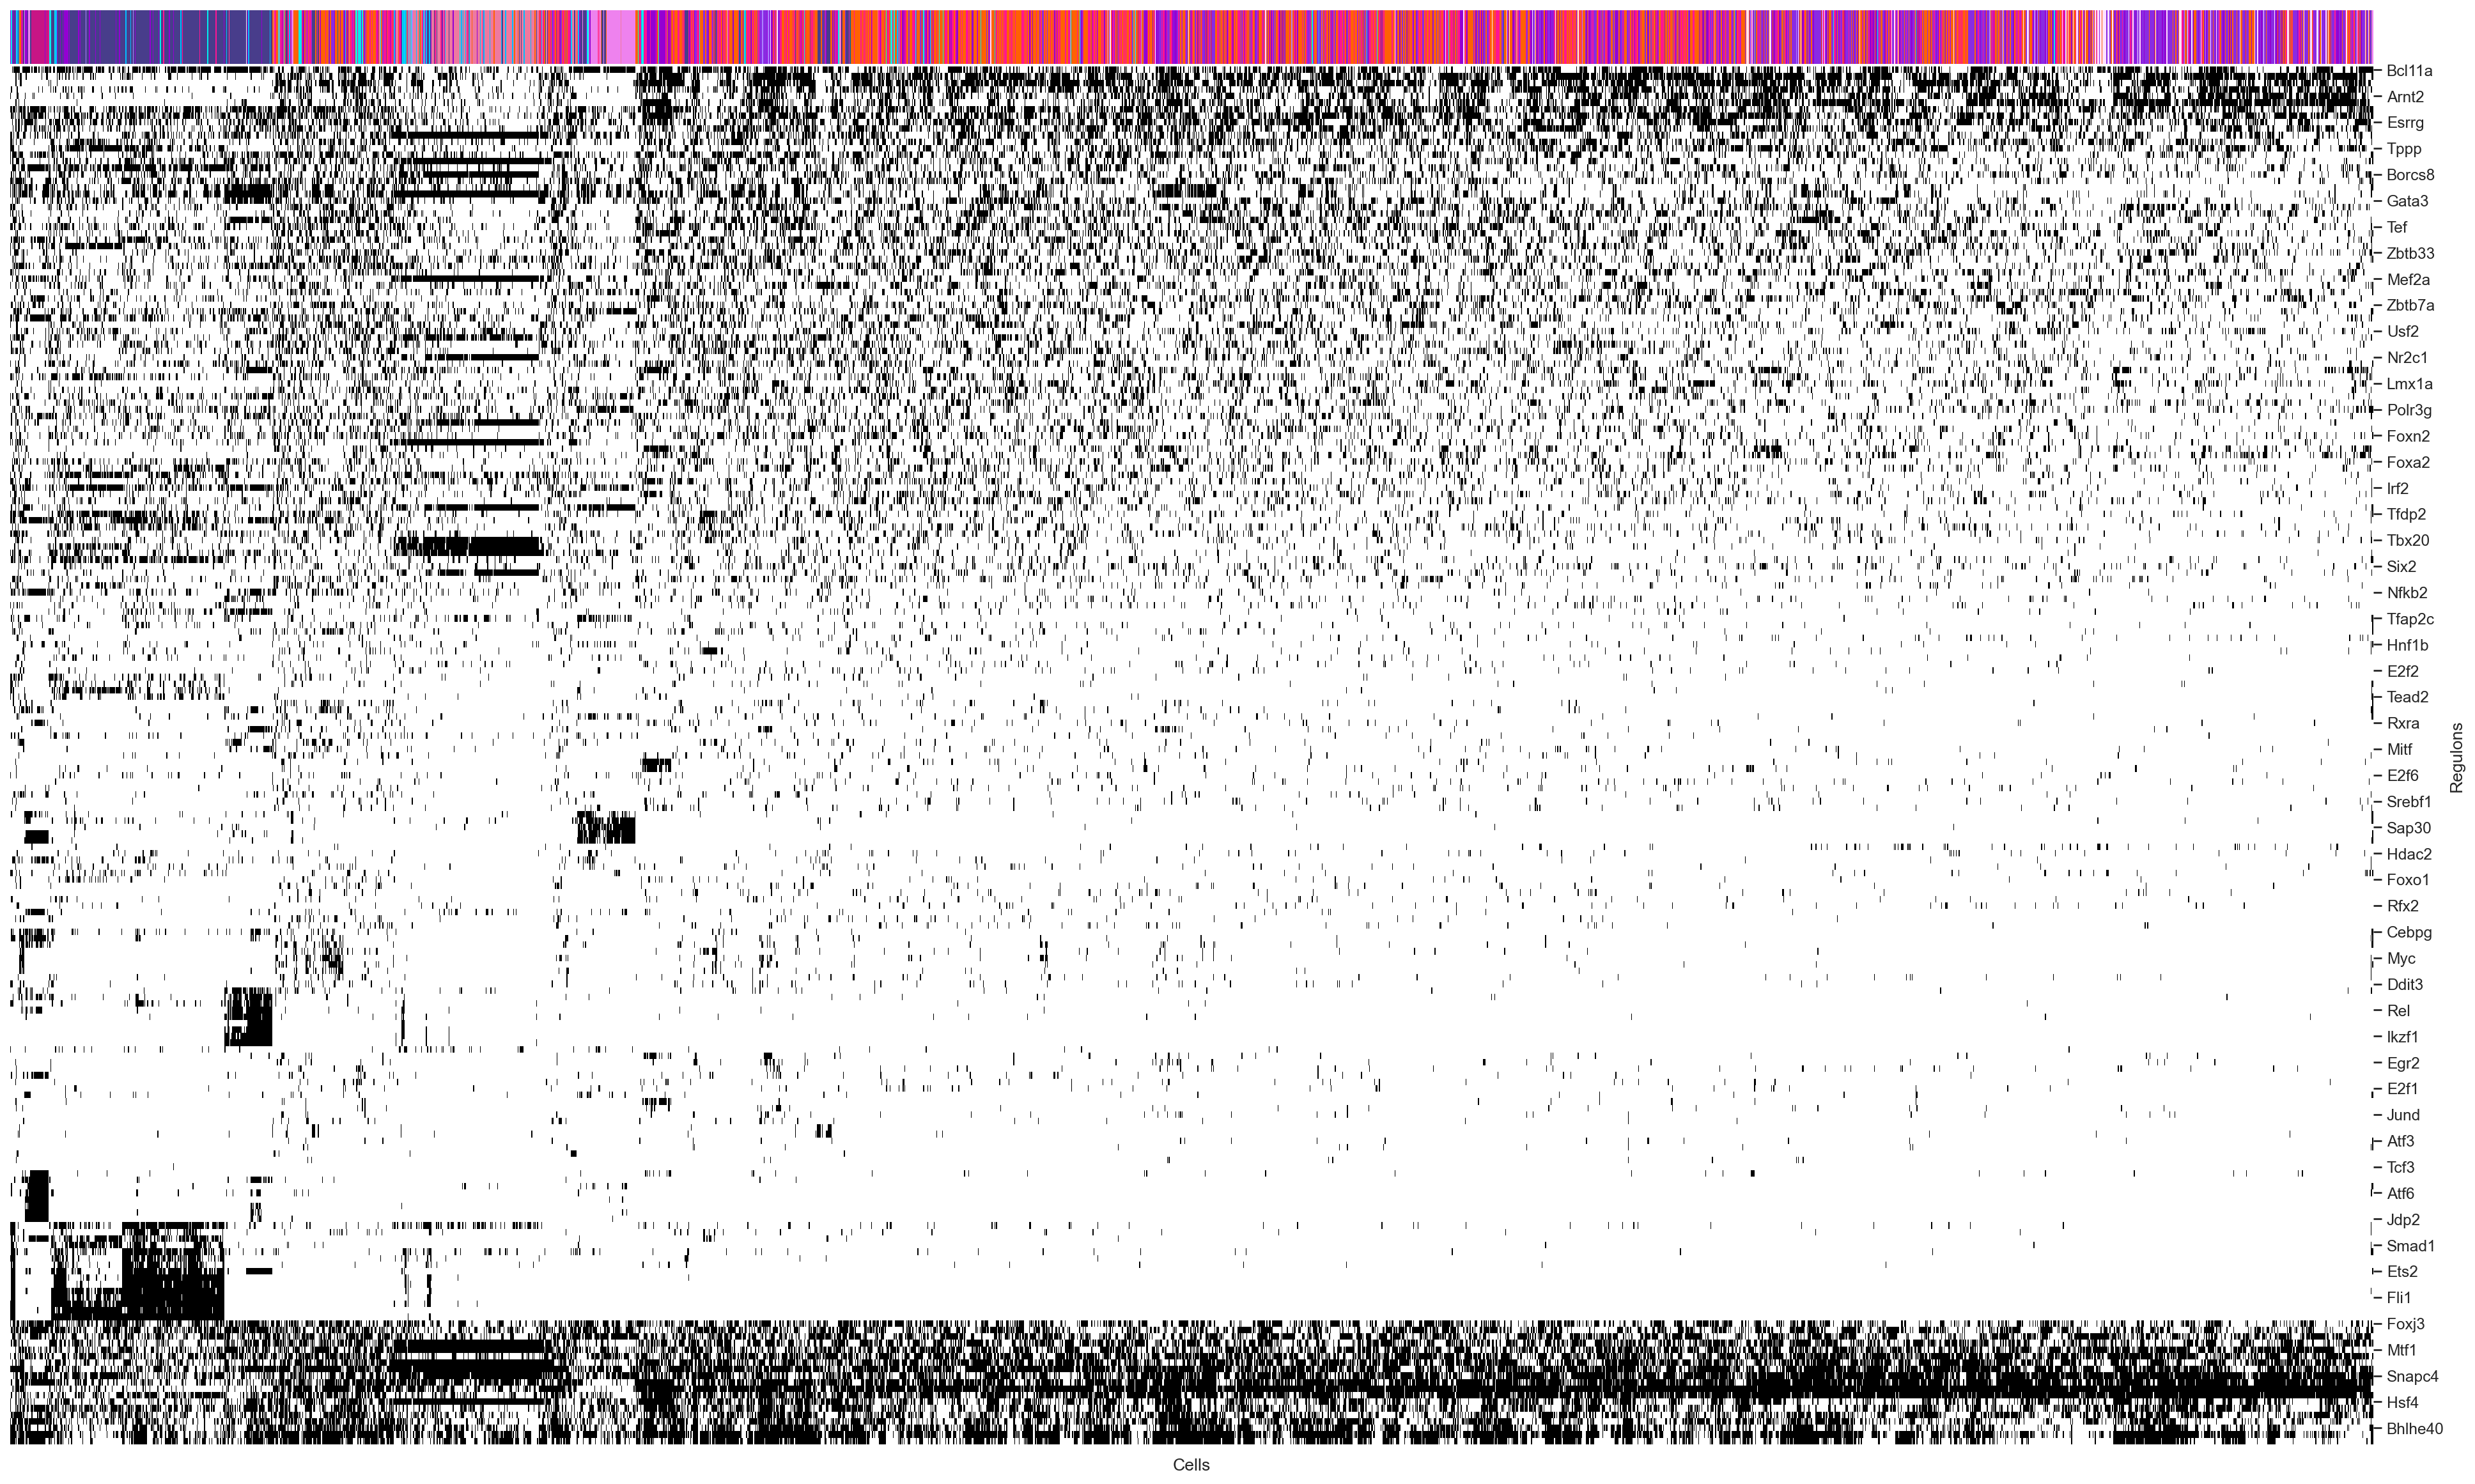

In [86]:
sns.set()
sns.set(font_scale=1)    # if do not reset later, this font size will affect all downstream plotting
sns.set_style("ticks", {"xtick.minor.size": 1, "ytick.minor.size": 0.1})
g = sns.clustermap(data=binary_mtx.T, figsize=(30,20),
                   col_colors=auc_mtx.index.map(CellID_to_pca_louvain_lut).map(pca_louvain_color_lut),
                   cmap=white_black_palette)
g.ax_heatmap.set_xticklabels([])
g.ax_heatmap.set_xticks([])
g.ax_heatmap.set_xlabel('Cells')
g.ax_heatmap.set_ylabel('Regulons')
g.ax_col_colors.set_yticklabels([])
g.ax_col_colors.set_yticks([])
g.ax_row_dendrogram.set_visible(False)
g.ax_col_dendrogram.set_visible(False)
g.cax.set_visible(False)
g.fig.savefig(os.path.join(FIGURES_FOLDERNAME, 'clustermap - CIS.pdf'), format='pdf')

In [87]:
# Save clustered binarized heatmap to Excel for further inspection
binary_mtx_clustered = binary_mtx.T.copy()
binary_mtx_clustered.rename(columns=adata.obs['pca_louvain'].to_dict(), inplace=True)
binary_mtx_clustered.iloc[g.dendrogram_row.reordered_ind, g.dendrogram_col.reordered_ind].to_excel(os.path.join(RESULTS_FOLDERNAME, 'CIS - Binarized regulon activity.xlsx'))

In [88]:
# Generate sequence logos
def fetch_logo(regulon, base_url = BASE_URL):
    for elem in regulon.context:
        if elem.endswith('.png'):
            return '<img src="{}{}" style="max-height:124px;"></img>'.format(base_url, elem)
    return ""

In [89]:
df_regulons = pd.DataFrame(data=[list(map(op.attrgetter('name'), regulons)),
                                 list(map(len, regulons)),
                                 list(map(fetch_logo, regulons))], index=['name', 'count', 'logo']).T

In [90]:
df_regulons.to_csv("/Users/KKo1/Documents/Ko/pyscenic/4NQO/CIS_motifs.csv")    # export the download addresses of motif logos

In [91]:
MAX_COL_WIDTH = pd.get_option('display.max_colwidth')
pd.set_option('display.max_colwidth', -1)
display(HTML(df_regulons.head().to_html(escape=False)))
pd.set_option('display.max_colwidth', MAX_COL_WIDTH)

,name,count,logo
0,Arnt,79,
1,Arnt2,10,
2,Arntl2,39,
3,Atf1,33,
4,Atf3,44,


In [92]:
MAX_COL_WIDTH = pd.get_option('display.max_colwidth')
pd.set_option('display.max_colwidth', -1)
display(HTML(df_regulons.to_html(escape=False)))
pd.set_option('display.max_colwidth', MAX_COL_WIDTH)

,name,count,logo
0,Arnt,79,
1,Arnt2,10,
2,Arntl2,39,
3,Atf1,33,
4,Atf3,44,
5,Atf4,343,
6,Atf6,348,
7,Bcl11a,16,
8,Bcl3,561,
9,Bhlhe40,32,


In [ ]:
# STEP 6: Non-linear projection and clustering

In [93]:
# We capture the non-linear projection based on PCA+umap for later storage in the loom file.
embedding_pca_umap = pd.DataFrame(adata.obsm['X_umap'], columns=[['_X', '_Y']], index=adata.obs_names)

In [94]:
adata

AnnData object with n_obs × n_vars = 2888 × 2528
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_louvain'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'louvain_colors', 'pca_louvain_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'

In [95]:
auc_mtx = pd.DataFrame(auc_mtx)
auc_mtx

,Arnt,Arnt2,Arntl2,Atf1,Atf3,Atf4,Atf6,Bcl11a,Bcl3,Bhlhe40,...,Zfp128,Zfp217,Zfp362,Zfp46,Zfp560,Zfp575,Zfp64,Zfp647,Zfp672,Zscan21
Cell,,,,,,,,,,,,,,,,,,,,,
AAAGCAAGTGCTTCTC,0.008879,0.000000,0.005383,0.025007,0.036022,0.033404,0.043787,0.040200,0.032592,0.000000,...,0.028193,0.017631,0.023379,0.022838,0.0,0.057767,0.071400,0.000383,0.081183,0.000000
AAATGCCTCCGCAGTG,0.015024,0.000000,0.033234,0.032473,0.071023,0.054414,0.033388,0.052109,0.035951,0.008647,...,0.000000,0.038835,0.031946,0.038835,0.0,0.008576,0.000000,0.000000,0.000000,0.000000
AACGTTGTCTGATACG,0.025608,0.000000,0.008464,0.026662,0.027251,0.045228,0.090761,0.034436,0.049465,0.000000,...,0.024972,0.003978,0.005069,0.107568,0.0,0.042799,0.032261,0.000000,0.062404,0.000000
AACACGTCAAGCGATG,0.013565,0.000000,0.045432,0.027618,0.073367,0.054537,0.032369,0.000000,0.037621,0.006144,...,0.000000,0.054072,0.024914,0.031664,0.0,0.003317,0.000000,0.000000,0.087251,0.000000
AAACGGGTCAGCATGT,0.021353,0.000000,0.000000,0.025228,0.255820,0.081845,0.046943,0.058556,0.059533,0.041262,...,0.008145,0.039273,0.032696,0.094881,0.0,0.095874,0.036913,0.000000,0.050332,0.082767
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCAAGCCTCGTG,0.025132,0.000000,0.009740,0.017027,0.140363,0.054000,0.071361,0.049302,0.063782,0.043310,...,0.023595,0.000000,0.041905,0.562776,0.0,0.096683,0.010316,0.000000,0.092936,0.087379
TTTGCGCGTTCGAATC,0.017943,0.000000,0.021845,0.042880,0.139315,0.073424,0.104732,0.000000,0.108849,0.013539,...,0.008705,0.174454,0.005390,0.180494,0.0,0.000000,0.000000,0.000000,0.174182,0.137379
TTTGCGCAGTACCGGA,0.018096,0.000000,0.017208,0.069616,0.158732,0.087216,0.186203,0.070312,0.105736,0.000000,...,0.000000,0.245314,0.061286,0.089144,0.0,0.054531,0.000000,0.000000,0.189512,0.071117


In [96]:
adata

AnnData object with n_obs × n_vars = 2888 × 2528
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_louvain'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand', 'n_cells', 'mt', 'rpl', 'rps', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'louvain_colors', 'pca_louvain_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced'
    obsp: 'distances', 'connectivities'

In [97]:
add_scenic_metadata(adata,auc_mtx,
                        regulons)

AnnData object with n_obs × n_vars = 2888 × 2528
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_louvain', 'Regulon(Arnt)', 'Regulon(Arnt2)', 'Regulon(Arntl2)', 'Regulon(Atf1)', 'Regulon(Atf3)', 'Regulon(Atf4)', 'Regulon(Atf6)', 'Regulon(Bcl11a)', 'Regulon(Bcl3)', 'Regulon(Bhlhe40)', 'Regulon(Borcs8)', 'Regulon(Cebpb)', 'Regulon(Cebpd)', 'Regulon(Cebpg)', 'Regulon(Creb1)', 'Regulon(Crem)', 'Regulon(Cux1)', 'Regulon(Dbp)', 'Regulon(Ddit3)', 'Regulon(Deaf1)', 'Regulon(Dlx5)', 'Regulon(E2f1)', 'Regulon(E2f2)', 'Regulon(E2f4)', 'Regulon(E2f6)', 'Regulon(E2f8)', 'Regulon(Egr1)', 'Regulon(Egr2)', 'Regulon(Egr4)', 'Regulon(Ehf)', 'Regulon(Elf1)', 'Regulon(Elf2)', 'Regulon(Elk3)', 'Regulon(Elk4)', 'Regulon(Ep300)', 'Regulon(Erg)', 'Regulon(Esrrg)', 'Regul

In [98]:
adata

AnnData object with n_obs × n_vars = 2888 × 2528
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_louvain', 'Regulon(Arnt)', 'Regulon(Arnt2)', 'Regulon(Arntl2)', 'Regulon(Atf1)', 'Regulon(Atf3)', 'Regulon(Atf4)', 'Regulon(Atf6)', 'Regulon(Bcl11a)', 'Regulon(Bcl3)', 'Regulon(Bhlhe40)', 'Regulon(Borcs8)', 'Regulon(Cebpb)', 'Regulon(Cebpd)', 'Regulon(Cebpg)', 'Regulon(Creb1)', 'Regulon(Crem)', 'Regulon(Cux1)', 'Regulon(Dbp)', 'Regulon(Ddit3)', 'Regulon(Deaf1)', 'Regulon(Dlx5)', 'Regulon(E2f1)', 'Regulon(E2f2)', 'Regulon(E2f4)', 'Regulon(E2f6)', 'Regulon(E2f8)', 'Regulon(Egr1)', 'Regulon(Egr2)', 'Regulon(Egr4)', 'Regulon(Ehf)', 'Regulon(Elf1)', 'Regulon(Elf2)', 'Regulon(Elk3)', 'Regulon(Elk4)', 'Regulon(Ep300)', 'Regulon(Erg)', 'Regulon(Esrrg)', 'Regul

In [99]:
# We add all metadata derived from SCENIC to the Scanpy AnnData object.
add_scenic_metadata(adata, auc_mtx, regulons)
adata.write_h5ad(ANNDATA_FNAME)

In [100]:
adata

AnnData object with n_obs × n_vars = 2888 × 2528
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_louvain', 'Regulon(Arnt)_x', 'Regulon(Arnt2)_x', 'Regulon(Arntl2)_x', 'Regulon(Atf1)_x', 'Regulon(Atf3)_x', 'Regulon(Atf4)_x', 'Regulon(Atf6)_x', 'Regulon(Bcl11a)_x', 'Regulon(Bcl3)_x', 'Regulon(Bhlhe40)_x', 'Regulon(Borcs8)_x', 'Regulon(Cebpb)_x', 'Regulon(Cebpd)_x', 'Regulon(Cebpg)_x', 'Regulon(Creb1)_x', 'Regulon(Crem)_x', 'Regulon(Cux1)_x', 'Regulon(Dbp)_x', 'Regulon(Ddit3)_x', 'Regulon(Deaf1)_x', 'Regulon(Dlx5)_x', 'Regulon(E2f1)_x', 'Regulon(E2f2)_x', 'Regulon(E2f4)_x', 'Regulon(E2f6)_x', 'Regulon(E2f8)_x', 'Regulon(Egr1)_x', 'Regulon(Egr2)_x', 'Regulon(Egr4)_x', 'Regulon(Ehf)_x', 'Regulon(Elf1)_x', 'Regulon(Elf2)_x', 'Regulon(Elk3)_x', 'Regulon(

In [101]:
# Add AUCell values as new representation (similar to a PCA). This facilitates the usage of
# AUCell as initial dimensional reduction.
adata.obsm['X_aucell'] = auc_mtx.values.copy()

In [102]:
adata

AnnData object with n_obs × n_vars = 2888 × 2528
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_louvain', 'Regulon(Arnt)_x', 'Regulon(Arnt2)_x', 'Regulon(Arntl2)_x', 'Regulon(Atf1)_x', 'Regulon(Atf3)_x', 'Regulon(Atf4)_x', 'Regulon(Atf6)_x', 'Regulon(Bcl11a)_x', 'Regulon(Bcl3)_x', 'Regulon(Bhlhe40)_x', 'Regulon(Borcs8)_x', 'Regulon(Cebpb)_x', 'Regulon(Cebpd)_x', 'Regulon(Cebpg)_x', 'Regulon(Creb1)_x', 'Regulon(Crem)_x', 'Regulon(Cux1)_x', 'Regulon(Dbp)_x', 'Regulon(Ddit3)_x', 'Regulon(Deaf1)_x', 'Regulon(Dlx5)_x', 'Regulon(E2f1)_x', 'Regulon(E2f2)_x', 'Regulon(E2f4)_x', 'Regulon(E2f6)_x', 'Regulon(E2f8)_x', 'Regulon(Egr1)_x', 'Regulon(Egr2)_x', 'Regulon(Egr4)_x', 'Regulon(Ehf)_x', 'Regulon(Elf1)_x', 'Regulon(Elf2)_x', 'Regulon(Elk3)_x', 'Regulon(

In [103]:
adata.write("CIS_after_clustermap.h5ad")

computing neighbors
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 8 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:12)


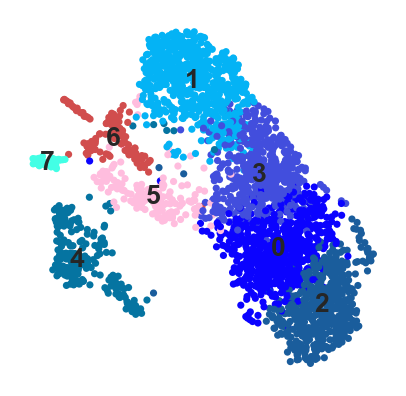

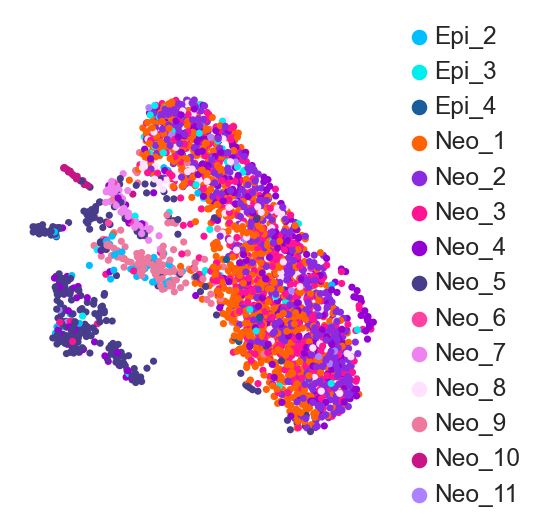

In [104]:
# AUCELL + umap PROJECTION
# We change the umap projection so that it relies on AUCell instead of PCA. Cells with similar regulons will cluster together.
sc.pp.neighbors(adata, n_pcs=50, use_rep='X_aucell')
sc.tl.louvain(adata, resolution=1)    # this 'louvain' is calculated by aucell
sc.tl.umap(adata)
embedding_aucell_umap = pd.DataFrame(adata.obsm['X_umap'], columns=[['_X', '_Y']], index=adata.obs_names)
sc.pl.umap(adata, color=['louvain'], use_raw=False, frameon=False, legend_loc='on data', title='', save=' - CIS - AUCell_umap.svg')
sc.pl.umap(adata, color=['pca_louvain'], use_raw=False, frameon=False, legend_loc='right margin', title='', save=' - CIS - pca_umap.svg')

In [105]:
sc.tl.rank_genes_groups(adata, groupby='louvain', method='wilcoxon', use_raw=False)
result = adata.uns['rank_genes_groups']
groups = result['names'].dtype.names
pd.DataFrame(
  {group + '_' + key[:3]: result[key][group]
    for group in groups for key in ['names', 'scores', 'logfoldchanges', 'pvals_adj']}).head(5000).to_csv("/Users/KKo1/Documents/Ko/pyscenic/4NQO/CIS_aucell_umap_markers.csv")

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:03)


In [106]:
# CELL TYPE SPECIFIC REGULATORS - Z-SCORE
df_obs = adata.obs
signature_column_names = list(df_obs.select_dtypes('number').columns)
signature_column_names = list(filter(lambda s: s.startswith('Regulon('), signature_column_names))
df_scores = df_obs[signature_column_names + ['pca_louvain']]
df_results = ((df_scores.groupby(by='pca_louvain').mean() - df_obs[signature_column_names].mean())/ df_obs[signature_column_names].std()).stack().reset_index().rename(columns={'level_1': 'regulon', 0:'Z'})
df_results['Regulon'] = list(map(lambda s: s[8:-1], df_results.regulon))
df_results[(df_results.Z >= 1)].sort_values(['pca_louvain', 'Z'], ascending=False)

,pca_louvain,regulon,Z,Regulon
5227,Neo_10,Regulon(Spdef)_x,9.121037,Spdef)_
5438,Neo_10,Regulon(Spdef)_y,9.121037,Spdef)_
5130,Neo_10,Regulon(Grhl1)_x,8.949603,Grhl1)_
5341,Neo_10,Regulon(Grhl1)_y,8.949603,Grhl1)_
5152,Neo_10,Regulon(Jdp2)_x,8.284064,Jdp2)_
...,...,...,...,...
236,Epi_2,Regulon(E2f8)_y,1.157160,E2f8)_
58,Epi_2,Regulon(Gata2)_x,1.049521,Gata2)_
269,Epi_2,Regulon(Gata2)_y,1.049521,Gata2)_
159,Epi_2,Regulon(Sox18)_x,1.022676,Sox18)_


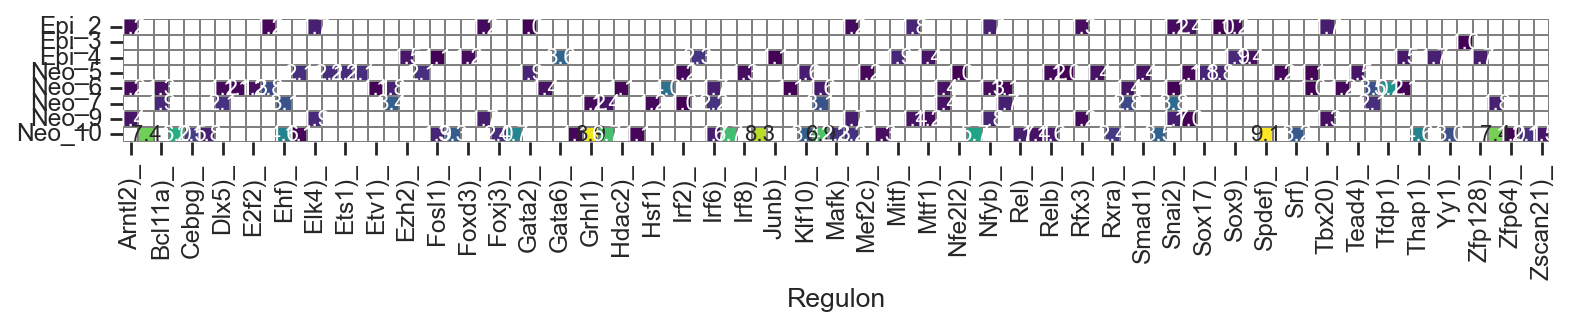

In [107]:
df_heatmap = pd.pivot_table(data=df_results[df_results.Z >= 1].sort_values('Z', ascending=False),
                           index='pca_louvain', columns='Regulon', values='Z')
fig, ax = plt.subplots(1, 1, figsize=(10, 8))
sns.heatmap(df_heatmap, ax=ax, annot=True, fmt=".1f", linewidths=.7, cbar=False, square=True, linecolor='gray', 
            cmap="viridis", annot_kws={"size": 10})
ax.set_ylabel('')
savesvg('heatmap - CIS - regulons.svg', fig)

In [108]:
# CELL TYPE SPECIFIC REGULATORS - RSS
rss = regulon_specificity_scores(auc_mtx, adata.obs['pca_louvain'])
rss

,Arnt,Arnt2,Arntl2,Atf1,Atf3,Atf4,Atf6,Bcl11a,Bcl3,Bhlhe40,...,Zfp128,Zfp217,Zfp362,Zfp46,Zfp560,Zfp575,Zfp64,Zfp647,Zfp672,Zscan21
Neo_1,0.404002,0.294903,0.344240,0.378815,0.404501,0.411002,0.399395,0.300659,0.399070,0.374157,...,0.393424,0.322653,0.385442,0.382673,0.223346,0.406598,0.344244,0.254336,0.393281,0.327520
Neo_9,0.210206,0.190994,0.279065,0.231427,0.210130,0.215346,0.212409,0.201674,0.215220,0.211073,...,0.199418,0.243730,0.227054,0.228697,0.187062,0.197195,0.187421,0.180146,0.215982,0.197792
Neo_5,0.259041,0.174930,0.261835,0.271510,0.239772,0.262160,0.287765,0.298017,0.279772,0.235005,...,0.260301,0.276718,0.256336,0.269079,0.227379,0.235179,0.242641,0.247752,0.287262,0.265513
Neo_3,0.329101,0.304508,0.299706,0.322697,0.334460,0.335370,0.320066,0.278866,0.325413,0.325957,...,0.320657,0.268615,0.320623,0.316701,0.209582,0.332356,0.308194,0.237397,0.306425,0.294838
Neo_2,0.328297,0.340695,0.271780,0.298645,0.341176,0.330346,0.327409,0.286800,0.330309,0.294482,...,0.283980,0.249530,0.328222,0.322389,0.184023,0.343050,0.288416,0.219383,0.328764,0.297262
Neo_8,0.211837,0.200842,0.199550,0.200150,0.207202,0.208808,0.210235,0.205001,0.208981,0.189773,...,0.197747,0.186220,0.215890,0.201808,0.181017,0.217300,0.200962,0.178017,0.216364,0.216188
Neo_7,0.191887,0.167445,0.201391,0.191519,0.191946,0.195341,0.200274,0.239404,0.195686,0.181634,...,0.184517,0.247289,0.194144,0.191247,0.183606,0.177228,0.186376,0.197892,0.201818,0.193099
Epi_2,0.185579,0.179651,0.213414,0.198851,0.182083,0.188573,0.189596,0.187151,0.188482,0.189890,...,0.193309,0.199778,0.193150,0.190631,0.182320,0.182225,0.183724,0.195018,0.188078,0.184856
Neo_4,0.286010,0.288054,0.257758,0.284232,0.291717,0.291982,0.288373,0.277804,0.290554,0.274820,...,0.266864,0.254955,0.285564,0.275345,0.210898,0.295043,0.291031,0.219616,0.283456,0.272270
Epi_3,0.196695,0.207673,0.200620,0.209432,0.192330,0.200532,0.200863,0.205827,0.198952,0.190971,...,0.206719,0.204247,0.194710,0.189033,0.178068,0.202357,0.196873,0.212796,0.196925,0.183508


In [109]:
rss.T.to_csv('/Users/KKo1/Documents/Ko/pyscenic/4NQO/RSS.csv')

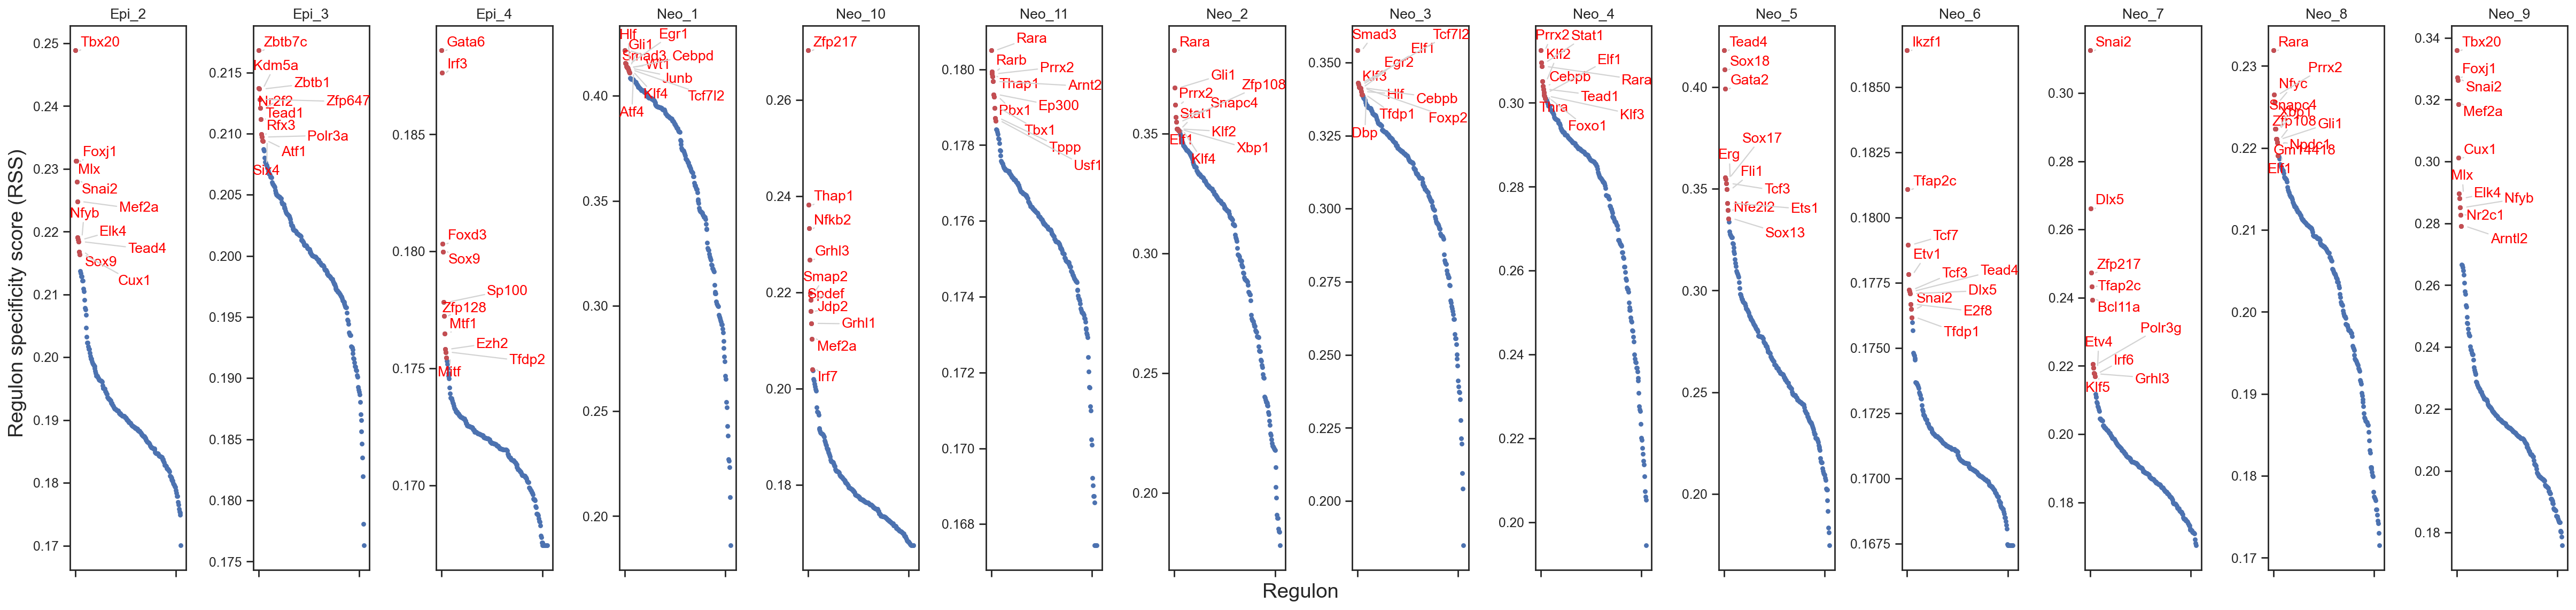

In [113]:
cats = sorted(list(set(adata.obs['pca_louvain'])))

fig = plt.figure(figsize=(30, 7))
for c,num in zip(cats, range(1,len(cats)+1)):
    x=rss.T[c]
    ax = fig.add_subplot(1,14,num)    # 1 means 1 row, 10 means 10 column
    plot_rss(rss, c, top_n=10, max_n=None, ax=ax)
    ax.set_ylim( x.min()-(x.max()-x.min())*0.05 , x.max()+(x.max()-x.min())*0.05)
    for t in ax.texts:
        t.set_fontsize(12)
    ax.set_ylabel('')
    ax.set_xlabel('')
    adjust_text(ax.texts, autoalign='xy', ha='right', va='bottom', arrowprops=dict(arrowstyle='-',color='lightgrey'), precision=0.001)
 
fig.text(0.5, 0.0, 'Regulon', ha='center', va='center', size='x-large')
fig.text(0.00, 0.5, 'Regulon specificity score (RSS)', ha='center', va='center', rotation='vertical', size='x-large')
plt.tight_layout()
plt.rcParams.update({
    'figure.autolayout': True,
        'figure.titlesize': 'large',
        'axes.labelsize': 'medium',
        'axes.titlesize':'large',
        'xtick.labelsize':'medium',
        'ytick.labelsize':'medium'
        })
savesvg('plots - CIS - rss.svg', fig)
plt.show()

In [114]:
adata

AnnData object with n_obs × n_vars = 2888 × 2528
    obs: 'Clusters', '_X', '_Y', 'initial_size_spliced', 'initial_size_unspliced', 'initial_size', 'sample_batch', 'louvain', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rpl', 'pct_counts_rpl', 'total_counts_rps', 'pct_counts_rps', 'pca_louvain', 'Regulon(Arnt)_x', 'Regulon(Arnt2)_x', 'Regulon(Arntl2)_x', 'Regulon(Atf1)_x', 'Regulon(Atf3)_x', 'Regulon(Atf4)_x', 'Regulon(Atf6)_x', 'Regulon(Bcl11a)_x', 'Regulon(Bcl3)_x', 'Regulon(Bhlhe40)_x', 'Regulon(Borcs8)_x', 'Regulon(Cebpb)_x', 'Regulon(Cebpd)_x', 'Regulon(Cebpg)_x', 'Regulon(Creb1)_x', 'Regulon(Crem)_x', 'Regulon(Cux1)_x', 'Regulon(Dbp)_x', 'Regulon(Ddit3)_x', 'Regulon(Deaf1)_x', 'Regulon(Dlx5)_x', 'Regulon(E2f1)_x', 'Regulon(E2f2)_x', 'Regulon(E2f4)_x', 'Regulon(E2f6)_x', 'Regulon(E2f8)_x', 'Regulon(Egr1)_x', 'Regulon(Egr2)_x', 'Regulon(Egr4)_x', 'Regulon(Ehf)_x', 'Regulon(Elf1)_x', 'Regulon(Elf2)_x', 'Regulon(Elk3)_x', 'Regulon(

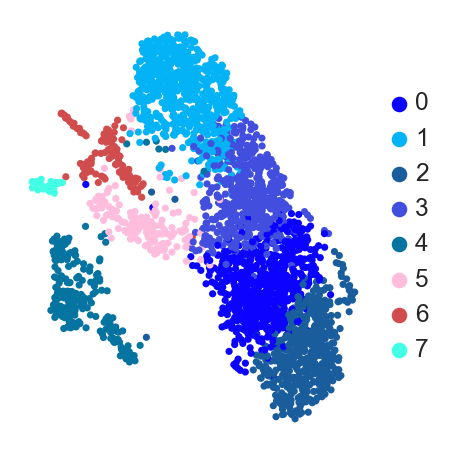

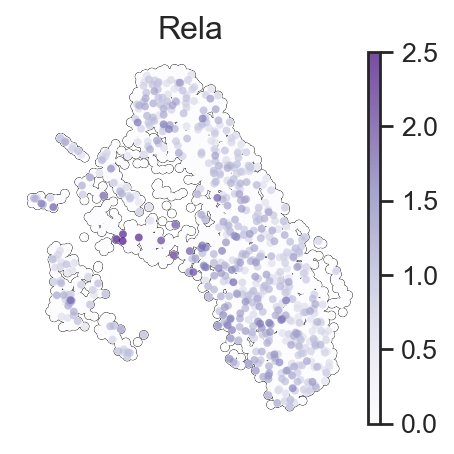

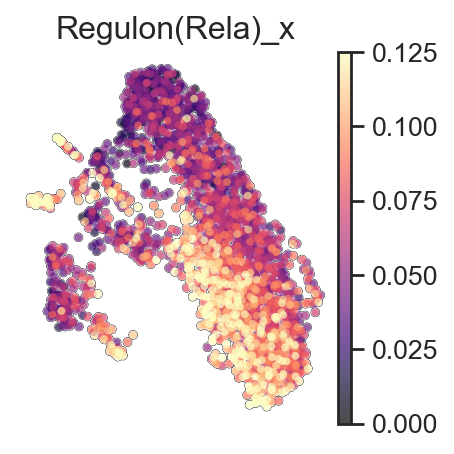

In [115]:
sc.pl.umap(adata, color=['louvain'], use_raw=False, frameon=False, legend_loc='right margin',
           title='', save=' - CIS - rss_aucell_louvain.svg')
sc.pl.umap(adata, color=['Rela'], use_raw=True, cmap='Purples', size=50,
           frameon=False, vmin=0,vmax=2.5, add_outline=True, outline_width=(0.05,0.05), save='- CIS - rss_Rela_gene.svg')
sc.pl.umap(adata, color=['Regulon(Rela)_x'], use_raw=True, cmap='magma', size=50,
           frameon=False, vmin=0,vmax=0.125, add_outline=True, outline_width=(0.05,0.05), save=' - CIS - rss_Rela_regulon.svg')

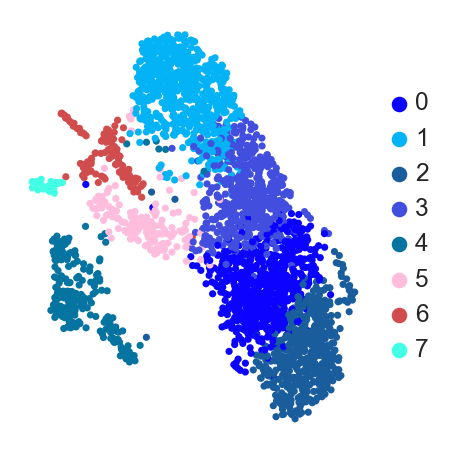

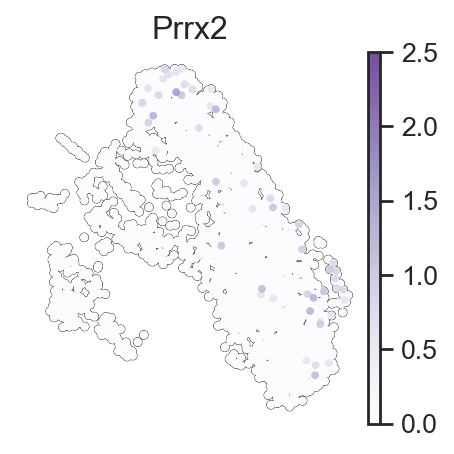

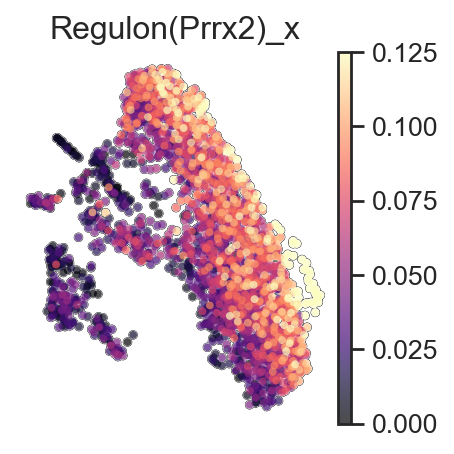

In [116]:
sc.pl.umap(adata, color=['louvain'], use_raw=False, frameon=False, legend_loc='right margin',
           title='', save=' - CIS - rss_aucell_louvain.svg')
sc.pl.umap(adata, color=['Prrx2'], use_raw=True, cmap='Purples', size=50,
           frameon=False, vmin=0, vmax=2.5,add_outline=True, outline_width=(0.05,0.05), save='- CIS - rss_Prrx2_gene.svg')
sc.pl.umap(adata, color=['Regulon(Prrx2)_x'], use_raw=True, cmap='magma', size=50,
           frameon=False, vmin=0, vmax=0.125,add_outline=True, outline_width=(0.05,0.05), save=' - CIS - rss_Prrx2_regulon.svg')

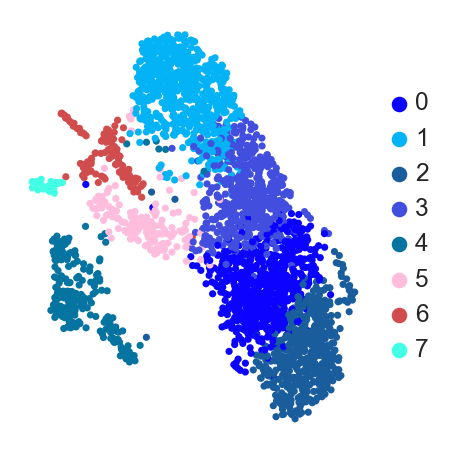

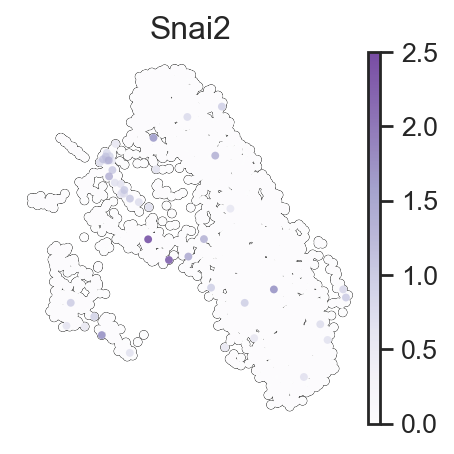

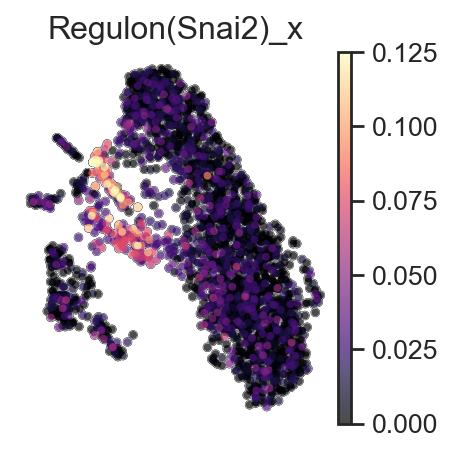

In [117]:
sc.pl.umap(adata, color=['louvain'], use_raw=False, frameon=False, legend_loc='right margin',
           title='', save=' - CIS - rss_aucell_louvain.svg')
sc.pl.umap(adata, color=['Snai2'], use_raw=True, cmap='Purples', size=50,
           frameon=False, vmin=0, vmax=2.5,add_outline=True, outline_width=(0.05,0.05), save='- CIS - rss_Snai2_gene.svg')
sc.pl.umap(adata, color=['Regulon(Snai2)_x'], use_raw=True, cmap='magma', size=50,
           frameon=False, vmin=0, vmax=0.125,add_outline=True, outline_width=(0.05,0.05), save=' - CIS - rss_Snai2_regulon.svg')

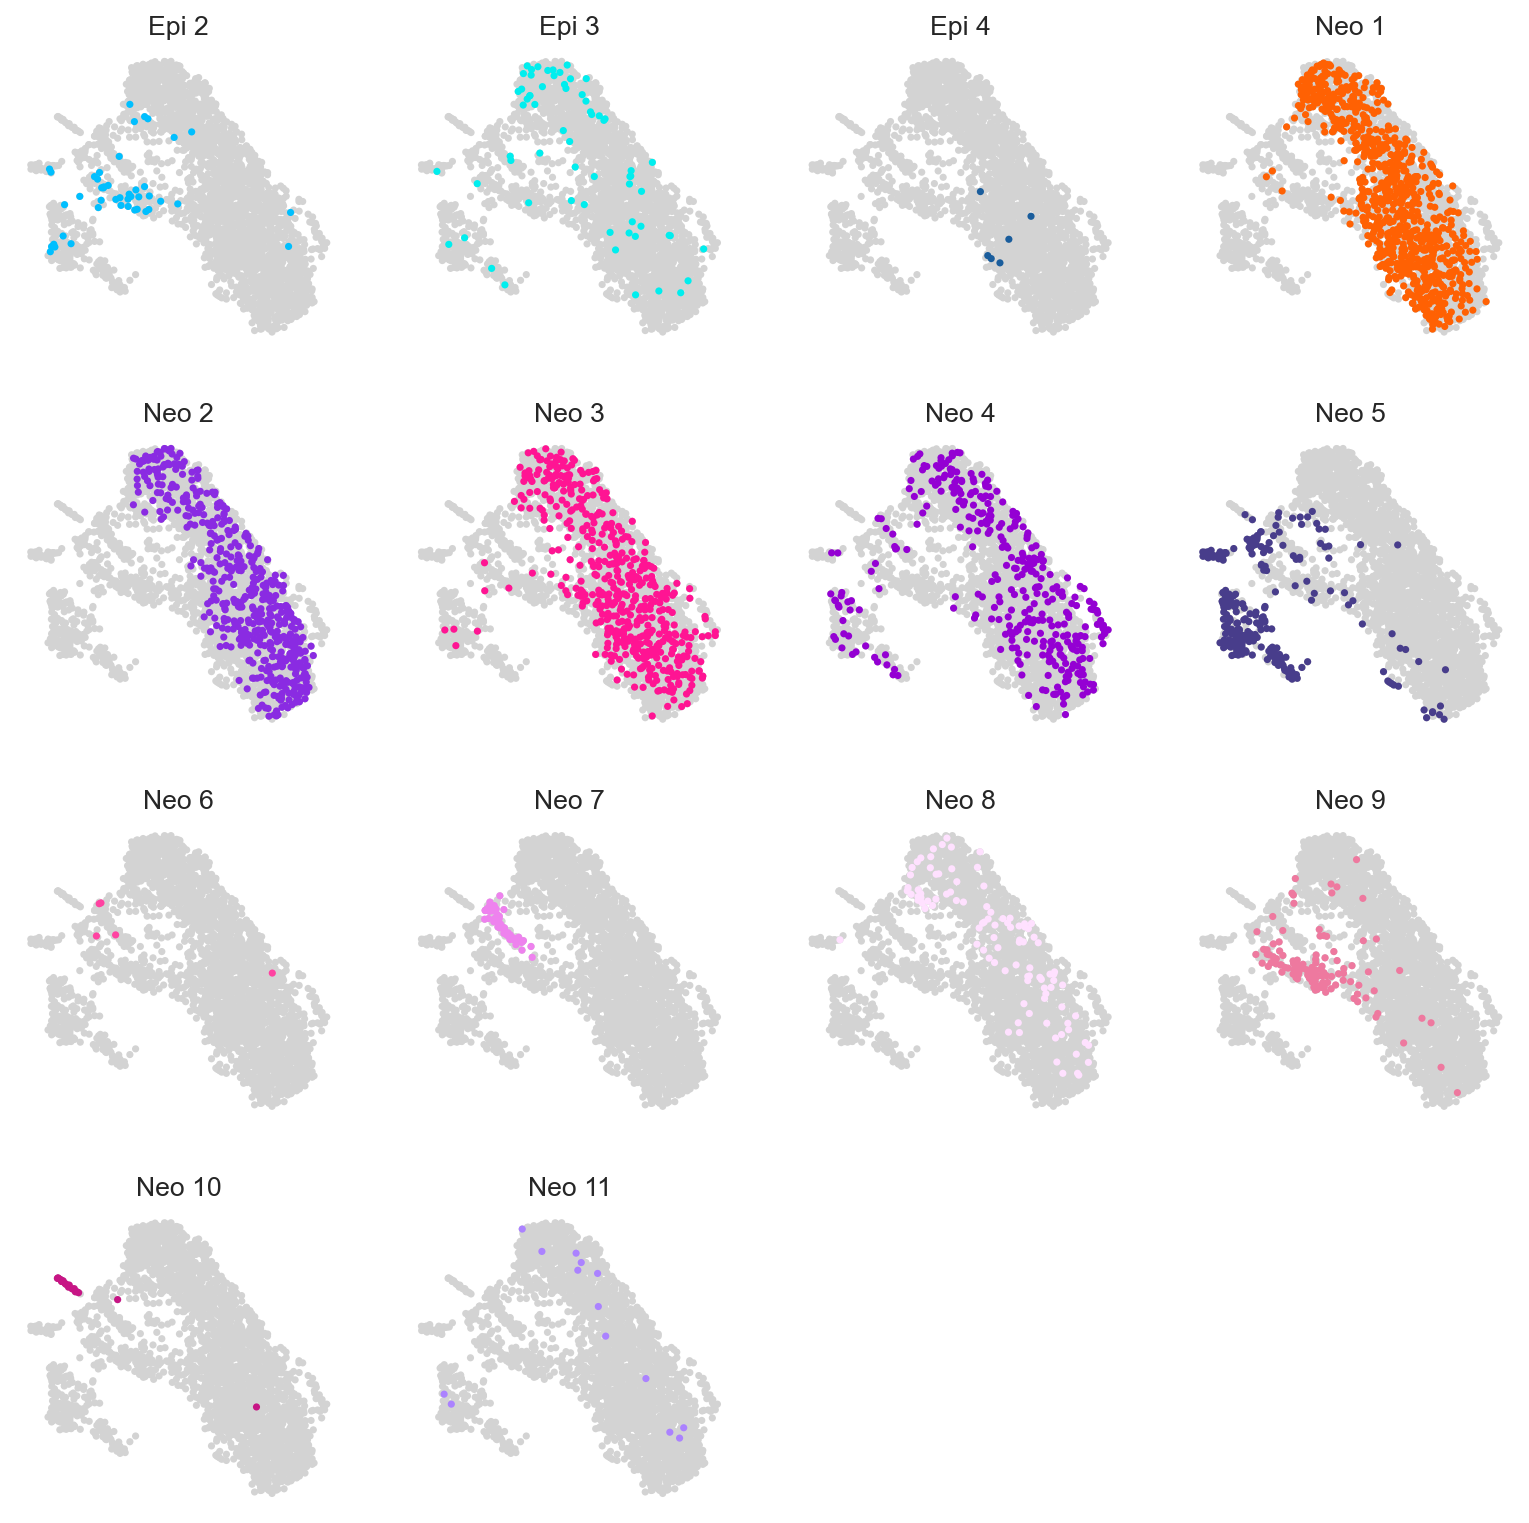

In [119]:
scv.pl.scatter(adata, groups=[[c] for c in adata.obs['pca_louvain'].cat.categories], color=['pca_louvain'], ncols=4)

In [120]:
# AUCELL DISTRIBUTIONS
# We can also analyze the distribution of AUCell values via the plots in the scanpy package.
df_results.sort_values('Z', ascending=False).groupby(by='pca_louvain').head(5)

,pca_louvain,regulon,Z,Regulon
5438,Neo_10,Regulon(Spdef)_y,9.121037,Spdef)_
5227,Neo_10,Regulon(Spdef)_x,9.121037,Spdef)_
5341,Neo_10,Regulon(Grhl1)_y,8.949603,Grhl1)_
5130,Neo_10,Regulon(Grhl1)_x,8.949603,Grhl1)_
5152,Neo_10,Regulon(Jdp2)_x,8.284064,Jdp2)_
...,...,...,...,...
1417,Neo_1,Regulon(Smad3)_x,0.260060,Smad3)_
1628,Neo_1,Regulon(Smad3)_y,0.260060,Smad3)_
1548,Neo_1,Regulon(Hlf)_y,0.244939,Hlf)_
1337,Neo_1,Regulon(Hlf)_x,0.244939,Hlf)_


In [121]:
aucell_adata = sc.AnnData(X=auc_mtx.sort_index())
aucell_adata.obs = df_obs
names = list(map(op.attrgetter('name'), filter(lambda r: r.score > 8.0, regulons)))
names

['E2f1', 'E2f8', 'Erg', 'Spi1']

In [122]:
aucell_adata.write("CIS_aucell_adata.h5ad")
adata.write("CIS_adata_after_rss.h5ad")

In [123]:
adata=sc.read("CIS_adata_after_rss.h5ad")

In [124]:
# STEP 7: Export to SCope

In [125]:
regulons = [r.rename(r.name.replace('(+)',' ('+str(len(r))+'g)')) for r in regulons]

In [126]:
regulons = [r.rename(r.name.replace('(',' (')) for r in regulons]

In [127]:
export2loom(ex_mtx=adata.to_df(), regulons=regulons, out_fname=LOOM_FNAME,
            cell_annotations=adata.obs['pca_louvain'].to_dict(), tree_structure=(),
            title='{}_{}'.format(TCGA_CODE, DATASET_ID), nomenclature="mm10", num_workers=16,
            embeddings=OrderedDict([('AUCell + umap', embedding_aucell_umap), ('PCA + umap', embedding_pca_umap)]),
            auc_mtx = auc_mtx, auc_thresholds=thresholds,
            compress=True)

Regulon name does not seem to be compatible with SCOPE. It should include a space to allow selection of the TF. 
Please run: 
 regulons = [r.rename(r.name.replace('(+)',' ('+str(len(r))+'g)')) for r in regulons] 
or:
 regulons = [r.rename(r.name.replace('(',' (')) for r in regulons]


In [128]:
# Step 8: Cytoscape-iRegulon exploration of modules

In [129]:
adjacencies = pd.read_csv(ADJACENCIES_FNAME, index_col=False, sep='\t')
adjacencies

,TF,target,importance
0,Rps4x,Rps3a1,1.522131e+02
1,Rps4x,Rpl9-ps6,1.465117e+02
2,Rps4x,Rps3,1.398479e+02
3,Rps4x,Rpl23,1.372282e+02
4,Rps4x,Rpl35,1.349953e+02
...,...,...,...
2925261,Hdx,Rgs5,8.258910e-20
2925262,Thrb,Ccl4,7.631883e-20
2925263,Hes6,Asprv1,6.105348e-20
2925264,Bhlhe40,Cxcl5,5.774267e-20


In [130]:
# Create the modules
from pyscenic.utils import modules_from_adjacencies
lf = lp.connect(f_loom_path_scenic, mode='r', validate=False)
exprMat = pd.DataFrame(lf[:,:], index=lf.ra.Gene, columns=lf.ca.CellID).T
modules = list(modules_from_adjacencies(adjacencies, exprMat))
lf.close()


2022-05-09 11:58:26,359 - pyscenic.utils - INFO - Calculating Pearson correlations.
INFO:pyscenic.utils:Calculating Pearson correlations.

2022-05-09 11:58:28,329 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].
	Dropout masking is currently set to [False].

2022-05-09 11:59:35,256 - pyscenic.utils - INFO - Creating modules.
INFO:pyscenic.utils:Creating modules.


In [131]:
# create a dictionary of regulons for converting the index from string to values:
lf2 = lp.connect(LOOM_FNAME, mode='r', validate=False)
regulons_dict = {}
for i,r in pd.DataFrame(lf2.ra.Regulons, index=lf2.ra.Gene).iteritems():
    regulons_dict[i] =  list(r[r==1].index.values)
lf2.close()

In [132]:
# pick out modules for Rela
tf = 'Rela'
tf_mods = [ x for x in modules if x.transcription_factor==tf ]

for i,mod in enumerate( tf_mods ):
    print( f'{tf} module {str(i)}: {len(mod.genes)} genes' )
print( f'{tf} regulon: {len(regulons_dict[tf])} genes' )

Rela module 0: 793 genes
Rela module 1: 241 genes
Rela module 2: 51 genes
Rela module 3: 20 genes
Rela module 4: 73 genes
Rela module 5: 785 genes
Rela regulon: 20 genes


In [133]:
# write these modules, and the regulon to files
for i,mod in enumerate( tf_mods ):
    with open( tf+'_module_'+str(i)+'.txt', 'w') as f:
        for item in mod.genes:
            f.write("%s\n" % item)
            
with open( tf+'_regulon.txt', 'w') as f:
    for item in regulons_dict[tf]:
        f.write("%s\n" % item)